# Bogotá: terreno y pendiente. 

Análisis exploratorio del terreno y pendiende de Bogotá

**Antes de**
1. Haber corrido el programa principal y los auxiliares, porque se necesitan los archivos de *datos_salida*, *datos_salida/auxiliares* y datos_entrada*.


## Archivos importantes, funciones de apoyo

Rutas de los archivos, colores de las gráficas y funciones de apoyo. La primera salida dice si cada archivo se encontró (OK) o no (FALTA).

In [4]:
import hashlib
import json
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

CARPETA = Path.cwd()
SALIDAS = CARPETA / "datos_salida"
AUX = SALIDAS / "auxiliares"
ENTRADAS = CARPETA / "datos_entrada"
RESPALDO = CARPETA / "respaldo_eda"

ARCHIVO_FINAL = SALIDAS / "bogota_pendientes_segmentos_mdt2020_v1.csv"
ARCHIVO_GPKG = ENTRADAS / "D2_segmentos_para_pendiente.gpkg"
ARCHIVO_EXACTITUD = SALIDAS / "bogota_exactitud_vertical_mdt2020_v1.csv"
ARCHIVO_CORRELACION = SALIDAS / "bogota_ancho_correlacion_v1.csv"
ARCHIVO_GRILLA = SALIDAS / "bogota_grilla_correlacion_v1.csv"
ARCHIVO_SENSIBILIDAD = SALIDAS / "bogota_sensibilidad_incertidumbre_v1.csv"
ARCHIVO_VERTICES = ENTRADAS / "igac_vertices_control_bogota.csv"
if not ARCHIVO_VERTICES.exists():
    ARCHIVO_VERTICES = CARPETA / "igac_vertices_control_bogota.csv"
ARCHIVO_SEPTIEMBRE = CARPETA / "pendiente_para_jhonny_sigma101_20260920_182450.csv"
ARCHIVO_CIERRE = CARPETA / "pendiente_final_sigma0.533_ancho53.6_20261012_154057.csv"


SIGMA_Z, ANCHO = 0.536, 53.6
SHA_ESPERADO = "445009d19b07"

AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9,
})

for ruta in [ARCHIVO_FINAL, ARCHIVO_GPKG, ARCHIVO_EXACTITUD, ARCHIVO_CORRELACION,
             ARCHIVO_SENSIBILIDAD, ARCHIVO_VERTICES, AUX, RESPALDO]:
    print(("OK      " if ruta.exists() else "FALTA   ") + str(ruta.relative_to(CARPETA)))

OK      datos_salida\bogota_pendientes_segmentos_mdt2020_v1.csv
OK      datos_entrada\D2_segmentos_para_pendiente.gpkg
OK      datos_salida\bogota_exactitud_vertical_mdt2020_v1.csv
OK      datos_salida\bogota_ancho_correlacion_v1.csv
OK      datos_salida\bogota_sensibilidad_incertidumbre_v1.csv
OK      datos_entrada\igac_vertices_control_bogota.csv
OK      datos_salida\auxiliares
OK      respaldo_eda


In [5]:
def mostrar(dato, valor, decimales=0):
    """Muestra un resultado con el número de decimales indicado."""
    #Para poder mostrar cada cifra 
    d = max(decimales, 0)
    print(f"{dato}: {float(valor):,.{d}f}")


def externa(dato, valor, fuente):
    """Cifra que no se recalcula con estos archivos: se muestra con su fuente."""
    #Son cifras de archivos externos, no se recalculan esos datos
    print(f"{dato}: {valor}  (fuente: {fuente})")


def verdadero(serie):
    # Convierte las columnas de tipo booleano a texto
    return serie.astype(str).str.strip().str.lower().eq("true")


def sin_tildes(texto):
    #Que no tenga problemas gramaticales y se reconozcan las palabras
    texto = unicodedata.normalize("NFKD", str(texto))
    return "".join(c for c in texto if not unicodedata.combining(c)).upper().strip()


def leer(ruta):
#Leer un CSV sin problemas de codificación y con separador automático
    return pd.read_csv(ruta, sep=None, engine="python", encoding="utf-8-sig")


def rmse(r):
    #Calcula el RMSEz, la raiz del promedio de los residuos al cuadrado
    r = pd.Series(r).dropna()
    return float(np.sqrt((r ** 2).mean()))


def nmad(r):
    #Calcula el NMADz, la dispersion que no se ve afectada por los valores extremos, usando la mediana de los residuos
    r = pd.Series(r).dropna()
    return float(1.4826 * np.median(np.abs(r - r.median())))


def error_pendiente(L, sigma=SIGMA_Z, ancho=ANCHO):
    #Calcula error de la pendiente con oz y el ancho de correlacion
    rho = 0.0 if ancho is None else np.exp(-np.asarray(L, float) / ancho)
    return 100 * np.sqrt(2 * sigma ** 2 * (1 - rho)) / np.asarray(L, float)


def piso_ruido(L, n, sigma=SIGMA_Z, ancho=ANCHO):
    #Calcula el piso de ruido de la acumulada
    p = np.asarray(L, float) / (np.asarray(n, float) - 1)
    sd = sigma * np.sqrt(2 * (1 - np.exp(-p / ancho)))
    return 100 * np.sqrt(2 / np.pi) * sd / p


def wilson(k, n, z=1.96):
    #Calcula el intervalo de confianza al 95% para una proporcion
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    e = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return 100 * (c - e), 100 * (c + e)

## Carga del archivo final

El archivo final tiene una fila por segmento dirigido.Se rectifica que sea el archivo correcto: su huella SHA-256 debe empezar por *445009d19b07*. La longitud de cada segmento y su localidad se toman del GeoPackage de la red, igual que en el programa principal, porque el contrato prohíbe recalcular la longitud.

Variables que se usan:
- *df*: los 225.704 segmentos.
- *con*: solo los que tienen dato del MDT (*fuera_cobertura_mdt* = False).
- *ext*: los que tienen *pendiente_extrema* = True.
- *tramo_fisico*: el identificador sin el sufijo FT o TF, que une los dos sentidos de una misma calle.

In [6]:
sha = hashlib.sha256(ARCHIVO_FINAL.read_bytes()).hexdigest()
print(f"SHA-256: {sha}")
print("Es el archivo entregado." if sha.startswith(SHA_ESPERADO) else "ATENCION: no es el archivo entregado.")

df = pd.read_csv(ARCHIVO_FINAL, float_precision="round_trip")
import geopandas as gpd
seg = gpd.read_file(ARCHIVO_GPKG, layer="segmentos", ignore_geometry=True)
df = df.merge(seg[[c for c in ["segmento_id", "longitud_m", "localidad"] if c in seg.columns]],
              on="segmento_id", how="left", validate="one_to_one")
for col in ["distinta_de_cero_2sigma", "pendiente_extrema", "fuera_cobertura_mdt"]:
    df[col] = verdadero(df[col])
partes = df["segmento_id"].str.rsplit("_", n=1)
df["tramo_fisico"], df["sentido"] = partes.str[0], partes.str[1]
df["neta_abs"] = df["pendiente_neta_pct"].abs()
df["loc"] = df["localidad"].map(lambda x: sin_tildes(x) if pd.notna(x) else "SIN LOCALIDAD")
fuera = df["fuera_cobertura_mdt"]
con = df[~fuera].copy()
ext = df[df["pendiente_extrema"]].copy()
print(f"{len(df):,} segmentos, {len(con):,} con dato, {len(ext):,} con pendiente extrema")
df.head()

SHA-256: 445009d19b07c61d7e0e789c5ab0adf3a56a794dec8640baf54e61c4ea560c4b
Es el archivo entregado.
225,704 segmentos, 224,330 con dato, 2,641 con pendiente extrema


,segmento_id,pendiente_neta_pct,pendiente_acumulada_pct,ganancia_elevacion_m,perdida_elevacion_m,z_inicio_m,z_fin_m,n_puntos_muestreados,paso_muestreo_m,clasificacion_invias,error_pendiente_pct,distinta_de_cero_2sigma,ruido_acumulada_pct,pendiente_extrema,fuera_cobertura_mdt,rho_correlacion,ancho_correlacion_m,sigma_z_m,longitud_m,localidad,tramo_fisico,sentido,neta_abs,loc
0,100000_0_FT,-1.194469,1.194469,0.000000,0.490722,2547.057861,2546.567139,2,50.0,Plano,1.350013,False,1.077155,False,False,0.464650,53.6,0.536,41.082864,SUBA,100000_0,FT,1.194469,SUBA
1,100000_0_TF,1.194469,1.194469,0.490722,0.000000,2546.567139,2547.057861,2,50.0,Plano,1.350013,False,1.077155,False,False,0.464650,53.6,0.536,41.082864,SUBA,100000_0,TF,1.194469,SUBA
2,100001_0_TF,-0.258156,0.258156,0.000000,0.162110,2550.685059,2550.522949,2,50.0,Plano,1.002796,False,0.800115,False,False,0.309884,53.6,0.536,62.795484,SUBA,100001_0,TF,0.258156,SUBA
3,100002_0_FT,1.027903,1.027903,0.177734,0.000000,2551.648926,2551.826660,2,50.0,Plano,2.301993,False,1.836725,False,False,0.724269,53.6,0.536,17.290925,SUBA,100002_0,FT,1.027903,SUBA
4,100002_0_TF,-1.027903,1.027903,0.000000,0.177734,2551.826660,2551.648926,2,50.0,Plano,2.301993,False,1.836725,False,False,0.724269,53.6,0.536,17.290925,SUBA,100002_0,TF,1.027903,SUBA


# 1. Caracterización del contexto

### Segmentos dirigidos con dato

Un **segmento dirigido** es un tramo de calle en un sentido de circulación, donde una calle de doble sentido aparece dos veces (FT y TF). Un segmento **tiene dato** cuando el MDT 2020 devolvió elevación en todos los puntos del perfil. Los que no lo tienen están en el borde de la cobertura del modelo y quedan con *fuera_cobertura_mdt = True*.

In [7]:
mostrar("segmentos dirigidos con dato", len(con))

segmentos dirigidos con dato: 224,330


### Elevación de la red

Se toman las elevaciones de los dos extremos de cada segmento con dato (*z_inicio_m* y *z_fin_m*). La **mediana** es el valor que deja la mitad de los puntos por debajo, el **percentil 95** es el valor que solo supera el 5 % más alto, el **máximo** es el punto más alto de la red vial. La diferencia entre la mediana (sabana) y el percentil 95 (laderas) muestra los dos relieves que se encuentran en la ciudad.

In [8]:
z = pd.concat([con["z_inicio_m"], con["z_fin_m"]])
mostrar("mediana de la elevacion en los extremos (m)", z.median(), 1)
mostrar("percentil 95 de la elevacion (m)", z.quantile(0.95), 1)
mostrar("elevacion maxima (m)", z.max(), 1)

mediana de la elevacion en los extremos (m): 2,555.9
percentil 95 de la elevacion (m): 2,853.7
elevacion maxima (m): 3,666.3


### Pendiente neta: mediana y percentiles

La **pendiente neta** compara solo la altura final con la inicial: 100 × (z_fin − z_inicio) / L. 
Aquí se usa su **valor absoluto**, ya que, subir o bajar 5 % es la misma inclinación. Que la mediana sea menor de 1% mientras el percentil 99 pasa de 36% muestra una distribución asimétrica, donde la mayoría de la red se encuentra en lo plano y una minoría es muy empinada.

In [9]:
a = con["neta_abs"]
mostrar("mediana de |neta| (%)", a.median(), 2)
mostrar("percentil 90 de |neta| (%)", a.quantile(0.90), 2)
mostrar("percentil 99 de |neta| (%)", a.quantile(0.99), 2)

mediana de |neta| (%): 0.76
percentil 90 de |neta| (%): 13.47
percentil 99 de |neta| (%): 36.48


### Clasificación INVIAS

El Manual de diseño geométrico del INVIAS (2008) clasifica el terreno por la pendiente:

 **Plano** menos de 3 %
 
 **Ondulado** de 3 a menos de 6 % 
 
 **Montañoso** de 6 a 8 % 
 
 **Escarpado** más de 8 % 
 
 La clasificación se hace sobre la pendiente neta absoluta. Se encuentra que la mayoría de los escarpados está entre 8 y 25 %, valores normales en vías de ladera, y que solo 2.563 superan 35 % por la neta que son valores a estudiar

In [10]:
CLASES = ["Plano", "Ondulado", "Montañoso", "Escarpado"]
cuenta = con["clasificacion_invias"].value_counts().reindex(CLASES)
for clase, n, pct in zip(CLASES, [159803, 16785, 8194, 39548], [71.24, 7.48, 3.65, 17.63]):
    mostrar(f"{clase}: segmentos", cuenta[clase])
    mostrar(f"{clase}: % de la red con dato", 100 * cuenta[clase] / len(con), 2)
mostrar("escarpados entre 8 y 15 %", ((a > 8) & (a <= 15)).sum())
mostrar("escarpados entre 15 y 25 %", ((a > 15) & (a <= 25)).sum())
mostrar("neta mayor de 35 %", (a > 35).sum())

Plano: segmentos: 159,803
Plano: % de la red con dato: 71.24
Ondulado: segmentos: 16,785
Ondulado: % de la red con dato: 7.48
Montañoso: segmentos: 8,194
Montañoso: % de la red con dato: 3.65
Escarpado: segmentos: 39,548
Escarpado: % de la red con dato: 17.63
escarpados entre 8 y 15 %: 20,768
escarpados entre 15 y 25 %: 12,611
neta mayor de 35 %: 2,563


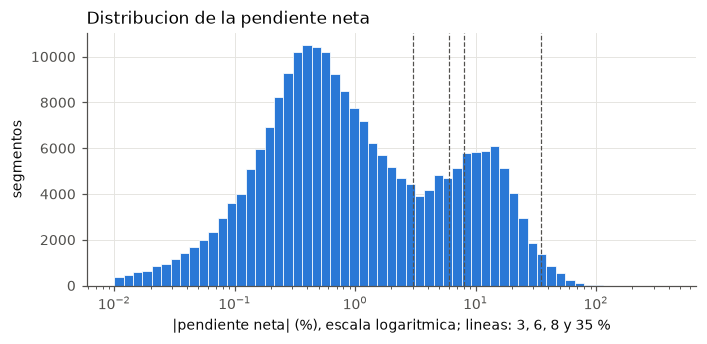

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(a[a >= 0.01], bins=np.logspace(-2, np.log10(400), 60), color=AZUL, edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
for lim in (3, 6, 8, 35):
    ax.axvline(lim, color=TINTA_2, linewidth=0.8, linestyle="--")
ax.set_xlabel("|pendiente neta| (%), escala logaritmica; lineas: 3, 6, 8 y 35 %")
ax.set_ylabel("segmentos")
ax.set_title("Distribucion de la pendiente neta", loc="left")
plt.tight_layout()
plt.show()

Es una distribución bimodal, ya que, se ven dos picos en la gráfica, donde la más grande son las calles de la sabana, mayormente planas y donde más se concentra la red, y la otra, son calles de ladera

### Concentración por localidad

Cada segmento se cruza con su localidad (columna *localidad* del GeoPackage). Las **siete localidades de ladera** son Ciudad Bolívar, Rafael Uribe Uribe, Usme, Usaquén, San Cristóbal, Santa Fe y Chapinero. Se mide qué parte de los segmentos escarpados y de los tramos extremos cae en alguna de ellas. Un **tramo físico** extremo se cuenta una sola vez aunque sus dos sentidos estén marcados

In [12]:
LADERA = ["CIUDAD BOLIVAR", "RAFAEL URIBE URIBE", "USME", "USAQUEN", "SAN CRISTOBAL", "SANTA FE", "CHAPINERO"]
con["loc"] = df.loc[con.index, "loc"]
ext["loc"] = df.loc[ext.index, "loc"]
esc = con["clasificacion_invias"].eq("Escarpado")
en7 = con["loc"].isin(LADERA)
mostrar("escarpados en las 7 localidades de ladera", (esc & en7).sum())
mostrar("% de los escarpados en esas 7", 100 * (esc & en7).sum() / esc.sum(), 1)
mostrar("% de los segmentos con dato en esas 7", 100 * en7.mean(), 1)
mostrar("% escarpado dentro de esas 7", 100 * esc[en7].mean(), 1)
mostrar("% escarpado en el resto de la ciudad", 100 * esc[~en7].mean(), 1)

escarpados en las 7 localidades de ladera: 37,727
% de los escarpados en esas 7: 95.4
% de los segmentos con dato en esas 7: 42.1
% escarpado dentro de esas 7: 40.0
% escarpado en el resto de la ciudad: 1.4


**Tabla 1.** 

Terreno escarpado y pendientes extremas por localidad. La participación es el porcentaje de los 1.328 tramos físicos extremos que cae en cada localidad.

In [13]:
fis = ext.drop_duplicates("tramo_fisico")
tabla1 = con.groupby("loc").agg(segmentos_con_dato=("segmento_id", "size"),
                                escarpado_pct=("clasificacion_invias", lambda s: 100 * (s == "Escarpado").mean()))
tabla1["tramos_extremos"] = fis.groupby("loc").size().reindex(tabla1.index).fillna(0).astype(int)
tabla1["participacion_pct"] = 100 * tabla1["tramos_extremos"] / fis.shape[0]
DOC_1 = {"SAN CRISTOBAL": (13893, 51.73, 101, 7.6), "USME": (17310, 47.85, 197, 14.8),
         "CIUDAD BOLIVAR": (27062, 46.59, 543, 40.9), "SANTA FE": (4433, 38.39, 54, 4.1),
         "CANDELARIA": (807, 36.56, 2, 0.2), "RAFAEL URIBE URIBE": (13740, 33.81, 278, 20.9),
         "CHAPINERO": (5353, 27.97, 34, 2.6), "USAQUEN": (12596, 14.34, 109, 8.2)}
for loc, (n, e, t, p) in DOC_1.items():
    f = tabla1.loc[loc]
    mostrar(f"{loc}: segmentos con dato", f["segmentos_con_dato"])
    mostrar(f"{loc}: % escarpado", f["escarpado_pct"], 2)
    mostrar(f"{loc}: tramos extremos", f["tramos_extremos"])
    mostrar(f"{loc}: participacion en los extremos (%)", f["participacion_pct"], 1)
tabla1.loc[list(DOC_1)].round(2)

SAN CRISTOBAL: segmentos con dato: 13,893
SAN CRISTOBAL: % escarpado: 51.73
SAN CRISTOBAL: tramos extremos: 101
SAN CRISTOBAL: participacion en los extremos (%): 7.6
USME: segmentos con dato: 17,310
USME: % escarpado: 47.85
USME: tramos extremos: 197
USME: participacion en los extremos (%): 14.8
CIUDAD BOLIVAR: segmentos con dato: 27,062
CIUDAD BOLIVAR: % escarpado: 46.59
CIUDAD BOLIVAR: tramos extremos: 543
CIUDAD BOLIVAR: participacion en los extremos (%): 40.9
SANTA FE: segmentos con dato: 4,433
SANTA FE: % escarpado: 38.39
SANTA FE: tramos extremos: 54
SANTA FE: participacion en los extremos (%): 4.1
CANDELARIA: segmentos con dato: 807
CANDELARIA: % escarpado: 36.56
CANDELARIA: tramos extremos: 2
CANDELARIA: participacion en los extremos (%): 0.2
RAFAEL URIBE URIBE: segmentos con dato: 13,740
RAFAEL URIBE URIBE: % escarpado: 33.81
RAFAEL URIBE URIBE: tramos extremos: 278
RAFAEL URIBE URIBE: participacion en los extremos (%): 20.9
CHAPINERO: segmentos con dato: 5,353
CHAPINERO: % es

,segmentos_con_dato,escarpado_pct,tramos_extremos,participacion_pct
loc,,,,
SAN CRISTOBAL,13893,51.73,101,7.61
USME,17310,47.85,197,14.83
CIUDAD BOLIVAR,27062,46.59,543,40.89
SANTA FE,4433,38.39,54,4.07
CANDELARIA,807,36.56,2,0.15
RAFAEL URIBE URIBE,13740,33.81,278,20.93
CHAPINERO,5353,27.97,34,2.56
USAQUEN,12596,14.34,109,8.21


Escarpado es la parte de las calles tiene mas del 8% de pendiente

Tramos extremos son mayores a 35% 

Participación pct indica en qué parte de todas las calles extremas de Bogotá está en esa localidad 

Localidades de sabana con muchos segmentos y casi nada escarpado, y concentración de los extremos en las siete de ladera. Los 197 segmentos sin localidad asignada están todos fuera de cobertura.

In [14]:
for loc, n in [("KENNEDY", 27747), ("ENGATIVA", 18920), ("BOSA", 17336)]:
    mostrar(f"{loc}: segmentos con dato", tabla1.loc[loc, "segmentos_con_dato"])
    mostrar(f"{loc}: escarpado menor de 0,6 %", float(tabla1.loc[loc, "escarpado_pct"] < 0.6))
mostrar("tramos fisicos extremos", fis.shape[0])
mostrar("tramos extremos en las 7 de ladera", fis["loc"].isin(LADERA).sum())
mostrar("% de los tramos extremos en esas 7", 100 * fis["loc"].isin(LADERA).mean(), 1)
mostrar("segmentos extremos en esas 7", ext["loc"].isin(LADERA).sum())
mostrar("% de los segmentos extremos en esas 7", 100 * ext["loc"].isin(LADERA).mean(), 1)
sin_loc = df["loc"].eq("SIN LOCALIDAD")
mostrar("segmentos sin localidad", sin_loc.sum())
mostrar("sin localidad que estan fuera de cobertura", (sin_loc & fuera).sum())

KENNEDY: segmentos con dato: 27,747
KENNEDY: escarpado menor de 0,6 %: 1
ENGATIVA: segmentos con dato: 18,920
ENGATIVA: escarpado menor de 0,6 %: 1
BOSA: segmentos con dato: 17,336
BOSA: escarpado menor de 0,6 %: 1
tramos fisicos extremos: 1,328
tramos extremos en las 7 de ladera: 1,316
% de los tramos extremos en esas 7: 99.1
segmentos extremos en esas 7: 2,620
% de los segmentos extremos en esas 7: 99.2
segmentos sin localidad: 197
sin localidad que estan fuera de cobertura: 197


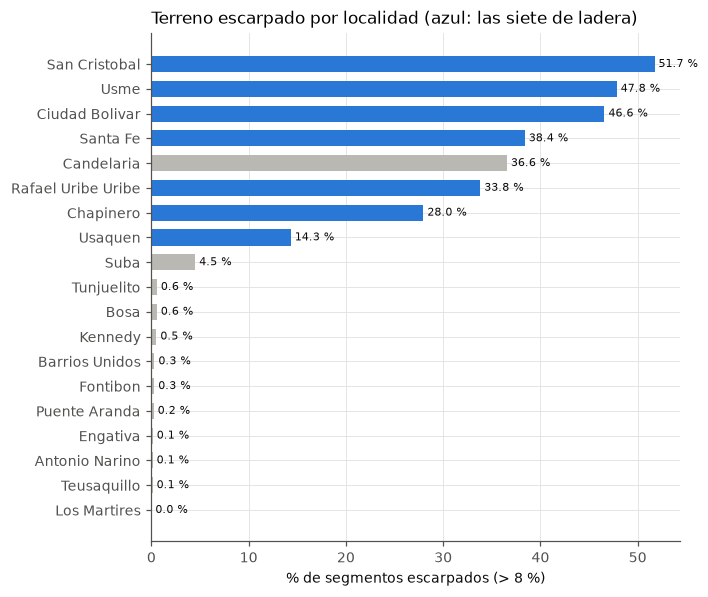

In [15]:
orden = tabla1.sort_values("escarpado_pct")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.barh(orden.index.str.title(), orden["escarpado_pct"], color=[AZUL if l in LADERA else "#b9b8b2" for l in orden.index], height=0.65)
for i, v in enumerate(orden["escarpado_pct"]):
    ax.text(v, i, f" {v:.1f} %", va="center", fontsize=7.5, color=TINTA)
ax.set_xlabel("% de segmentos escarpados (> 8 %)")
ax.set_title("Terreno escarpado por localidad (azul: las siete de ladera)", loc="left")
plt.tight_layout()
plt.show()

Con respecto a la localidad de Candelaria se resalta en gris, puesto que, el ranking se armó por la cantidad y no el porcentaje, son las siete localidades que más segmentos escarpados tienen, en está gráfica muestra que tiene una proporción alta pero con pocos semgentos (807)

# 2. Enfoque y diseño



### 2.1 El segmento dirigido y la simetría FT/TF

Los 225.704 segmentos dirigidos vienen de 130.424 tramos físicos: Los que tienen los dos sentidos aparecen dos veces y los de un solo sentido, una vez. Como la pendiente es positiva cuando el tramo sube en el sentido de la fila, los dos sentidos de un mismo tramo deben tener la misma pendiente solo que con signo contrario. Se comprueba sumando las dos netas: el resultado debe ser cero salvo errores de redondeo de la máquina, y la altura de inicio de un sentido debe ser exactamente la de fin del otro.

In [16]:
mostrar("segmentos dirigidos", len(df))
mostrar("tramos fisicos", df["tramo_fisico"].nunique())
por_tramo = df.groupby("tramo_fisico").size()
mostrar("tramos con los dos sentidos", (por_tramo == 2).sum())
mostrar("tramos con un solo sentido", (por_tramo == 1).sum())
piv = df.pivot_table(index="tramo_fisico", columns="sentido", values=["pendiente_neta_pct", "z_inicio_m", "z_fin_m"])
pares = piv.dropna(subset=[("pendiente_neta_pct", "FT"), ("pendiente_neta_pct", "TF")])
suma = (pares[("pendiente_neta_pct", "FT")] + pares[("pendiente_neta_pct", "TF")]).abs()
cruce = (pares[("z_inicio_m", "FT")] - pares[("z_fin_m", "TF")]).abs()
mostrar("pares FT/TF con dato en los dos sentidos", len(pares))
print(f"        suma maxima de las dos netas: {suma.max():.1e}")
mostrar("suma de netas menor de 1e-13 en todos los pares", float(suma.max() < 1e-13))
mostrar("inicio FT igual a fin TF en todos los pares", float(cruce.max() == 0))

segmentos dirigidos: 225,704
tramos fisicos: 130,424
tramos con los dos sentidos: 95,280
tramos con un solo sentido: 35,144
pares FT/TF con dato en los dos sentidos: 94,600
        suma maxima de las dos netas: 2.1e-14
suma de netas menor de 1e-13 en todos los pares: 1
inicio FT igual a fin TF en todos los pares: 1


### 2.2 Pendiente neta y acumulada

La **acumulada** suma en valor absoluto todas las subidas y bajadas del perfil. Siempre es mayor o igual que la neta. Cuando la supera por mucho, el tramo sube y baja por dentro.

In [17]:
dif = con["pendiente_acumulada_pct"] - con["neta_abs"]
mostrar("acumulada mayor que la neta en mas de 2 pp", (dif > 2).sum())
om = con[con["clasificacion_invias"].isin(["Ondulado", "Montañoso"]) & (con["pendiente_acumulada_pct"] > 35)]
mostrar("Ondulado o Montanoso con acumulada > 35 %", len(om))
mostrar("tramos fisicos de esos segmentos", om["tramo_fisico"].nunique())
mostrar("maxima acumulada de esos segmentos (%)", om["pendiente_acumulada_pct"].max(), 2)

acumulada mayor que la neta en mas de 2 pp: 3,255
Ondulado o Montanoso con acumulada > 35 %: 16
tramos fisicos de esos segmentos: 8
maxima acumulada de esos segmentos (%): 69.84


In [18]:
# Segmentos con neta moderada (Ondulado o Montañoso) pero acumulada mayor de 35 %
moderados = con[con["clasificacion_invias"].isin(["Ondulado", "Montañoso"])
                & (con["pendiente_acumulada_pct"] > 35)]

caso = moderados.sort_values("pendiente_acumulada_pct", ascending=False).iloc[0]
print(f"Caso más marcado: {caso['segmento_id']}")
print(f"  neta: {caso['pendiente_neta_pct']:.2f} %")
print(f"  acumulada: {caso['pendiente_acumulada_pct']:.2f} %")
print(f"  longitud: {caso['longitud_m']:.1f} m, puntos medidos: {int(caso['n_puntos_muestreados'])}")

moderados[["segmento_id", "clasificacion_invias", "pendiente_neta_pct",
           "pendiente_acumulada_pct", "longitud_m", "n_puntos_muestreados"]] \
    .sort_values("pendiente_acumulada_pct", ascending=False).round(2)

Caso más marcado: 48216_0_FT
  neta: -7.66 %
  acumulada: 69.84 %
  longitud: 28.4 m, puntos medidos: 3


,segmento_id,clasificacion_invias,pendiente_neta_pct,pendiente_acumulada_pct,longitud_m,n_puntos_muestreados
133285,48216_0_FT,Montañoso,-7.66,69.84,28.39,3
133286,48216_0_TF,Montañoso,7.66,69.84,28.39,3
71101,142301_0_TF,Ondulado,4.21,52.58,125.46,13
71100,142301_0_FT,Ondulado,-4.21,52.58,125.46,13
215327,94348_0_FT,Montañoso,-6.89,43.13,39.85,4
215328,94348_0_TF,Montañoso,6.89,43.13,39.85,4
112891,36749_0_FT,Ondulado,-3.76,39.11,31.93,4
112892,36749_0_TF,Ondulado,3.76,39.11,31.93,4
11882,10739_0_FT,Montañoso,7.58,38.99,66.45,7
11883,10739_0_TF,Montañoso,-7.58,38.99,66.45,7


En las calles donde la acumulada es mayor que la neta en más de 2 puntos, que son 3.255 segmentos, da indicio que es importante no usar solo la neta, ya que no se ve las lomas dentro de ese tramo.

Ondulado o Montanoso con acumulada > 35 %: 16, son las calles que por su neta parecen moderadas (3% a 8%) pero cuya acumulada para de 35%, el caso más fuerte tiene neta de 7,66% y acumulada 69,84%, donde de punta a punta sube poco, pero en el camino tiene saltos enormes, lo cual son casos extraños, que puede ser que cruce algo que el modelo de terreno no representa como la vía, ya sea, un muro un puente. Estas se denominan como pendientes extremas, porque la regla usa la mayor entre la neta y la acumulada.

### 2.3 Error de la pendiente según la longitud

El error de la pendiente neta sale del error vertical del MDT (σz = 0,536 m) y de la correlación entre puntos cercanos (ρ = exp(−L/53,6)):

error = 100 × √(2 σz² (1 − ρ)) / L

En tramos cortos el error es grande porque una diferencia de altura pequeña se divide por una longitud pequeña. Si se ignorara la correlación (ρ = 0), el error a 10 m sería más del doble.

error de la pendiente a 10 m (pp): 3.13
error de la pendiente a 20 m (pp): 2.12
error de la pendiente a 50 m (pp): 1.18
error de la pendiente a 100 m (pp): 0.70
error a 10 m con errores independientes (pp): 7.58


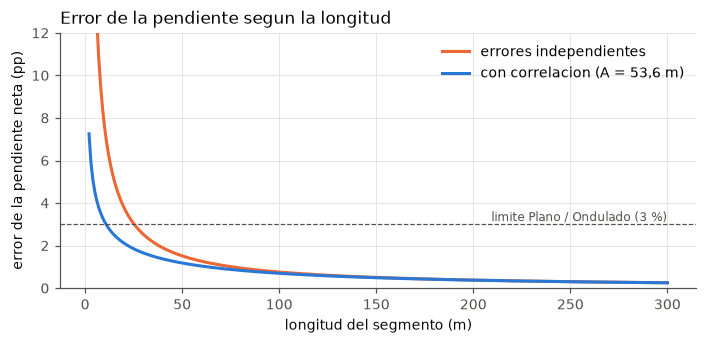

In [19]:
for largo, valor in [(10, 3.13), (20, 2.12), (50, 1.18), (100, 0.70)]:
    mostrar(f"error de la pendiente a {largo} m (pp)", error_pendiente(largo), 2)
mostrar("error a 10 m con errores independientes (pp)", error_pendiente(10, ancho=None), 2)

largos = np.linspace(2, 300, 300)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(largos, error_pendiente(largos, ancho=None), color=NARANJA, linewidth=2, label="errores independientes")
ax.plot(largos, error_pendiente(largos), color=AZUL, linewidth=2, label="con correlacion (A = 53,6 m)")
ax.axhline(3, color=TINTA_2, linewidth=0.8, linestyle="--")
ax.text(300, 3.15, "limite Plano / Ondulado (3 %)", ha="right", color=TINTA_2, fontsize=8)
ax.set_ylim(0, 12)
ax.set_xlabel("longitud del segmento (m)")
ax.set_ylabel("error de la pendiente neta (pp)")
ax.set_title("Error de la pendiente segun la longitud", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

1. El error baja cuando el segmento es más largo, la curva cae rápido al prinpio y luego se aplana, la razón es por la fórmula, el error de las dos alturas se reparte sobre la longitud, así que una misma incertidumbre vertical pesa mucho en un tramo de 10 m y casi nada en uno de 200 m. 
2. La correlación reduce en buena medida el error en los segmentos cortos, suponer independencia sobrestimaría el error donde puede importar.
3. La curvas se juntan alrededor de los 100 a 150m, a esa distancia los dos extremos ya están demasiado lejos para compartir error, porque la correlación se pierde al pasar el alcance (160,9m).


# 3. Datos y fuentes de información

### 3.1 Referencia vertical del MDT 2020

Ninguna fuente declara si las alturas del MDT son ortométricas (sobre el nivel del mar) o elipsoidales. Por esa razón, se estableció con los datos: Si fueran elipsoidales, el MDT quedaría por encima de los vértices del IGAC en la **ondulación del geoide** (la distancia entre el elipsoide y el nivel del mar), que en Bogotá es de unos 25 m. Aquí se compara el sesgo del MDT frente a los 496 vértices adoptados con esa ondulación, calculada con el modelo GEOCOL2004 en los mismos vértices (*aux_referencia_vertical_geoide.py*).

In [20]:
ex = pd.read_csv(ARCHIVO_EXACTITUD)
ex = ex[ex["residuo_m"].notna() & ~verdadero(ex["excluir"])]
mostrar("vertices adoptados", len(ex))
mostrar("sesgo medio del MDT frente al IGAC (m)", ex["residuo_m"].mean(), 2)
mostrar("mediana del sesgo (m)", ex["residuo_m"].median(), 2)
GEOIDE = ENTRADAS / "GEOCOL2004_20191118.isg.txt"
ond = None
if GEOIDE.exists():
    texto = GEOIDE.read_text(encoding="latin-1")
    cab, datos = texto.split("end_of_head", 1)
    h = {}
    for linea in cab.splitlines():
        if "=" in linea and not linea.startswith("begin_of_head"):
            k_, v_ = linea.split("=", 1)
            try:
                h[k_.strip()] = float(v_)
            except ValueError:
                pass
    malla = np.array(datos.split("\n", 1)[1].split(), float)[: int(h["nrows"]) * int(h["ncols"])]
    malla = malla.reshape(int(h["nrows"]), int(h["ncols"]))
    i = (h["lat max"] - ex["lat"].to_numpy()) / h["delta lat"] - 0.5
    j = (ex["lon"].to_numpy() - h["lon min"]) / h["delta lon"] - 0.5
    i0, j0 = np.floor(i).astype(int), np.floor(j).astype(int)
    fi, fj = i - i0, j - j0
    ond = (malla[i0, j0] * (1 - fi) * (1 - fj) + malla[i0, j0 + 1] * (1 - fi) * fj
           + malla[i0 + 1, j0] * fi * (1 - fj) + malla[i0 + 1, j0 + 1] * fi * fj)
elif (AUX / "referencia_vertical_geoide.csv").exists():
    ond = leer(AUX / "referencia_vertical_geoide.csv")["ondulacion_geoide_m"].to_numpy()
if ond is not None:
    mostrar("ondulacion del geoide, media (m)", ond.mean(), 1)
    mostrar("ondulacion del geoide, minimo (m)", ond.min(), 1)
    mostrar("ondulacion del geoide, maximo (m)", ond.max(), 1)
    print(f"Si el MDT fuera elipsoidal, el sesgo seria cercano a {ond.mean():.1f} m; es {ex['residuo_m'].mean():+.2f} m: alturas ortometricas.")
else:
    externa("ondulacion del geoide en los vertices", "25,5 m (24,8 a 26,9)", "aux_referencia_vertical_geoide.py con GEOCOL2004")

vertices adoptados: 496
sesgo medio del MDT frente al IGAC (m): -0.12
mediana del sesgo (m): -0.02
ondulacion del geoide, media (m): 25.5
ondulacion del geoide, minimo (m): 24.8
ondulacion del geoide, maximo (m): 26.9
Si el MDT fuera elipsoidal, el sesgo seria cercano a 25.5 m; es -0.12 m: alturas ortometricas.


Hay dos formas de medir la altura
1. Ortométrica: Sobre el nivel medio del mar. Es la altura “normal” que usan los mapas y los vértices del IGAC.
2. Elipsoidal: Sobre el elipsoide, una superficie matemática lisa que usan los GPS.

En Bogotá las dos superficies están separadas unos 25 m. Esa separación es la ondulación del geoide. Por eso un mismo punto puede tener dos alturas que difieren unos 25 m según cuál se use.

Los resultados muestran que el MDT usa la misma referencia que el IGAC, las alturas ortométricas, sobre el nivel del mar, si fuera elipsoidal la diferencia hubiera sido mucho mayor. 

### 3.2 Cambio de OpenStreetMap a la Malla Vial
La primera versión usó la red de OpenStreetMap. En la corrida, el 10 % de sus nodos quedó sin elevación, lo que junto con la falta de un identificador común con el grafo llevó a cambiar a la Malla Vial de IDECA.

In [21]:
externa("nodos de OSM sin elevacion", "6.765 de 67.835 (10,0 %)", "corrida de produccion sobre OSM")

nodos de OSM sin elevacion: 6.765 de 67.835 (10,0 %)  (fuente: corrida de produccion sobre OSM)


### 3.3 Vértices de control del IGAC

El IGAC publica 591 vértices de nivelación en Bogotá. Se usan solo los de **coordenada calculada**, porque en los de coordenada aproximada no se puede garantizar que el MDT se consulte sobre la placa. Los años de cálculo y el tipo de materialización salen del shapefile del IGAC (la mayoría son medidos en 2001). Los dos vértices atípicos de la muestra resultaron tener coordenada aproximada.

In [22]:
red = pd.read_csv(RESPALDO / "igac_red_nivelacion_bogota_20261013.csv")
mostrar("vertices del IGAC en Bogota", len(red))
mostrar("con coordenada calculada", red["tipo_coord"].eq("CALCULADA").sum())
mostrar("con coordenada aproximada", red["tipo_coord"].eq("APROXIMADA").sum())
anios = red["ano_calcul"].value_counts()
for ano, n in [(2001, 257), (1986, 86), (2024, 79), (1999, 73)]:
    mostrar(f"vertices calculados en {ano}", anios.get(ano, 0))
aprox = red.set_index("nomenclatu").loc[["1-CM-5", "10-E-1"], "tipo_coord"]
mostrar("1-CM-5 y 10-E-1 con coordenada aproximada", float((aprox == "APROXIMADA").all()))
red["tipo_mat"].value_counts().rename("vertices").to_frame()

vertices del IGAC en Bogota: 591
con coordenada calculada: 530
con coordenada aproximada: 61
vertices calculados en 2001: 257
vertices calculados en 1986: 86
vertices calculados en 2024: 79
vertices calculados en 1999: 73
1-CM-5 y 10-E-1 con coordenada aproximada: 1


,vertices
tipo_mat,
MOJON,265
INCRUSTACION,249
PILASTRA,15
CORS PISO,1


Tipo_mat es el tipo de materialización, cómo está marcado fisicamente el punto en el terreno, que es importante porque la altura del IGAC es la de esa marca 

### 3.4 Descarte del MDT 2025

El MDT 2025 se midió contra los vértices de la primera validación, la muestra de 85 vértices. Se usan los 79 que siguen materializados y tienen dato del MDT 2020: Se quitan 5 destruidos y 1-CM-17, que está fuera de la cobertura del MDT 2020. El **RMSEz** es la raíz del promedio de los residuos al cuadrado; el **NMAD** es una medida de dispersión que no se afecta por valores atípicos. El MDT 2020 es más exacto en todas las medidas.

**Tabla 5** 
MDT 2020 frente a MDT 2025, medidos contra los 79 vértices materializados de la primera validación.

In [23]:
m25 = pd.read_csv(RESPALDO / "exactitud_vertical_mdt2025_20261012.csv")
m25 = m25[~m25["vertice"].str.endswith("DEST") & m25["dif_2020_m"].notna()]
sin2 = m25[~m25["vertice"].isin(["1-CM-5", "10-E-1"])]
mostrar("vertices materializados de la primera validacion", len(m25))
tabla5 = pd.DataFrame({
    "MDT 2020": [rmse(m25["dif_2020_m"]), rmse(sin2["dif_2020_m"]), m25["dif_2020_m"].median(), nmad(m25["dif_2020_m"])],
    "MDT 2025": [rmse(m25["dif_2025_m"]), rmse(sin2["dif_2025_m"]), m25["dif_2025_m"].median(), nmad(m25["dif_2025_m"])]},
    index=["RMSEz, 79 vertices (m)", "RMSEz sin 1-CM-5 y 10-E-1, 77 vertices (m)", "Mediana del residuo (m)", "NMAD (m)"])
DOC_5 = [(1.033, 1.168), (0.533, 0.773), (0.047, -0.120), (0.334, 0.552)]
for fila, (v20, v25) in zip(tabla5.index, DOC_5):
    mostrar(f"{fila}, MDT 2020", tabla5.loc[fila, "MDT 2020"], 3)
    mostrar(f"{fila}, MDT 2025", tabla5.loc[fila, "MDT 2025"], 3)
tabla5.round(3)

vertices materializados de la primera validacion: 79
RMSEz, 79 vertices (m), MDT 2020: 1.033
RMSEz, 79 vertices (m), MDT 2025: 1.168
RMSEz sin 1-CM-5 y 10-E-1, 77 vertices (m), MDT 2020: 0.533
RMSEz sin 1-CM-5 y 10-E-1, 77 vertices (m), MDT 2025: 0.773
Mediana del residuo (m), MDT 2020: 0.047
Mediana del residuo (m), MDT 2025: -0.120
NMAD (m), MDT 2020: 0.334
NMAD (m), MDT 2025: 0.552


,MDT 2020,MDT 2025
"RMSEz, 79 vertices (m)",1.033,1.168
"RMSEz sin 1-CM-5 y 10-E-1, 77 vertices (m)",0.533,0.773
Mediana del residuo (m),0.047,-0.120
NMAD (m),0.334,0.552


Antes de adoptar el MDT 2020 se evaluó si el modelo más reciente de IDECA, el de 2025, podía reemplazarlo. Para la evaluación se utilizaron los mismos puntos, necesario para que la diferencia entre los resultados se debiera a los modelos y no a la muestra.

Con los 79 vértices, el MDT 2020 tuvo un RMSEz de 1,033 m y el de 2025, de 1,168 m. Las dos cifras son altas porque dos vértices, 1-CM-5 y 10-E-1, tienen residuos muy grandes en ambos modelos. Al quitarlos, el RMSEz baja a 0,533 m en el MDT 2020 y a 0,773 m en el de 2025. Que el error caiga en los dos modelos a la vez indica que el problema estaba en esos vértices y no en los MDT, más adelante se comprueba que ambos tienen coordenada aproximada, de modo que el modelo se consultaba en un punto que no corresponde a la placa.

El NMAD, que mide la dispersión sin dejarse arrastrar por los atípicos, lleva a la misma conclusión: 0,334 m en el MDT 2020 y 0,552 m en el de 2025, cerca de un 65 % más. Las medianas, de +0,05 m y −0,12 m, están cerca de cero en los dos, así que ninguno está corrido hacia arriba o hacia abajo, la diferencia está en cuánto se dispersan sus errores.

 Parte de esa dispersión puede venir de que el MDT 2025 entrega sus alturas redondeadas a metro entero, aunque el redondeo no alcanza a explicar toda la diferencia. A esto se suma un problema, con alturas en metros enteros y un paso de muestreo de 10 m, las pendientes calculadas solo pueden cambiar en saltos de 10 %, lo que las hace casi inútiles en calles de poca inclinación. Por estas dos razones, menor exactitud y alturas redondeadas, se mantuvo el MDT 2020 como fuente de elevación.

# 4. Métodos y herramientas


### 4.1 Consulta de elevaciones

Justificación del por qué consultar punto por punto que se hicieron contra el servicio del MDT, y sus resultados quedaron en la bitácora.

In [24]:
externa("prueba A: lote de 5 puntos con uno sin dato", "5 enviados, 2 recibidos", "aux_alineacion_consulta.py")
externa("prueba B: 700 puntos por lote y uno a uno", "694 identicos, 6 con 2 a 7 cm", "aux_alineacion_consulta.py")
externa("checkpoint", "310.525 puntos, 36.041 sin valor", "reconsulta")
externa("recuperados y confirmados fuera", "1.763 y 34.278", "reconsulta")

prueba A: lote de 5 puntos con uno sin dato: 5 enviados, 2 recibidos  (fuente: aux_alineacion_consulta.py)
prueba B: 700 puntos por lote y uno a uno: 694 identicos, 6 con 2 a 7 cm  (fuente: aux_alineacion_consulta.py)
checkpoint: 310.525 puntos, 36.041 sin valor  (fuente: reconsulta)
recuperados y confirmados fuera: 1.763 y 34.278  (fuente: reconsulta)


La consulta por lotes perdía puntos cuando el lote incluía uno sin dato, la consulta individual da los mismos valores cuando el lote funciona y recuperó 1.763 puntos, lo que dejó con pendiente 2.596 segmentos que antes no la tenían

### 4.2 Exactitud vertical: filtros previos

Antes de mirar cualquier residuo (MDT − IGAC) se quitan los vértices cuya referencia no sirve, fuera del MDT urbano, sin dato del MDT y destruidos. Quedan los **candidatos**: materializados con dato. Se cruzan con el archivo de vértices para tener el tipo de materialización, el año.

In [25]:
v = pd.read_csv(ARCHIVO_EXACTITUD)
ctrl = pd.read_csv(ARCHIVO_VERTICES)
v = v.merge(ctrl[["vertice", "tipo_mat", "ano_calcul", "en_muestra_original", "fuera_mdt_urbano"]], on="vertice", how="left")
amp = pd.read_csv(RESPALDO / "exactitud_ampliada_vertices_20261013.csv")
v = v.merge(amp[["vertice", "zona"]], on="vertice", how="left")
for c in ["excluir", "en_muestra_original", "fuera_mdt_urbano"]:
    v[c] = verdadero(v[c])
con_dato = v["residuo_m"].notna()
mat = con_dato & v["estado_geovisor"].str.lower().eq("materializado")
mostrar("vertices con coordenada calculada", len(v))
mostrar("fuera del MDT urbano", v["fuera_mdt_urbano"].sum())
mostrar("dentro del MDT pero sin dato", (~con_dato & ~v["fuera_mdt_urbano"]).sum())
mostrar("destruidos (con dato)", (con_dato & ~mat).sum())
mostrar("candidatos: materializados con dato", mat.sum())

vertices con coordenada calculada: 530
fuera del MDT urbano: 12
dentro del MDT pero sin dato: 1
destruidos (con dato): 13
candidatos: materializados con dato: 504


De los 530 vértices con coordenada calculada se descartaron, antes de calcular cualquier residuo, 12 fuera de la cobertura del MDT, 1 sin dato y 13 destruidos, con lo que quedaron 504 candidatos

### 4.2 Umbral de investigación en dos etapas

La guía de la ASPRS (Flood, 2004) indica investigar todo residuo mayor que **tres desviaciones estándar**. En la etapa 1, con los 504 candidatos, tres residuos de varios metros inflan la desviación y el umbral queda en 10,18 m. En la etapa 2 se recalcula sin esos tres y el umbral baja a 2,64 m, que superan cinco vértices más. Los ocho que superan algún umbral son exactamente los excluidos con evidencia en el archivo de vértices.

In [26]:
s1 = v.loc[mat, "residuo_m"].std()
bajo1 = mat & (v["residuo_m"].abs() <= 3 * s1)
s2 = v.loc[bajo1, "residuo_m"].std()
mostrar("desviacion etapa 1 (m)", s1, 2)
mostrar("umbral etapa 1 (m)", 3 * s1, 2)
mostrar("vertices bajo el umbral 1", bajo1.sum())
mostrar("desviacion etapa 2 (m)", s2, 2)
mostrar("umbral etapa 2 (m)", 3 * s2, 2)
superan1 = v.loc[mat & ~bajo1, ["vertice", "residuo_m"]]
superan2 = v.loc[bajo1 & (v["residuo_m"].abs() > 3 * s2), ["vertice", "residuo_m"]]
print("Etapa 1:", superan1.round(2).values.tolist())
print("Etapa 2:", superan2.round(2).values.tolist())
excluidos = sorted(v.loc[v["excluir"] & mat, "vertice"])
mostrar("los excluidos son los 8 que superan los umbrales", float(sorted(list(superan1["vertice"]) + list(superan2["vertice"])) == excluidos))

desviacion etapa 1 (m): 3.39
umbral etapa 1 (m): 10.18
vertices bajo el umbral 1: 501
desviacion etapa 2 (m): 0.88
umbral etapa 2 (m): 2.64
Etapa 1: [['18-BGT-1', 61.4], ['CAR1', -34.77], ['CD-323A', -20.42]]
Etapa 2: [['BOGOTA-19', -8.52], ['CD-109A', -5.76], ['CD-445', -3.24], ['CD-543', -9.91], ['CD-840', -6.96]]
los excluidos son los 8 que superan los umbrales: 1


**Tabla 7.** Derivación de σz a partir de los vértices del IGAC. En cada paso, σz es el RMSEz de los vértices que quedan.

 Vértices excluidos en la investigación de atípicos. El residuo es la altura del MDT 2020 menos la altura publicada por el IGAC.

| Etapa | Vértice | Residuo (m) | Tipo de causa | Evidencia |
|---|---|---|---|---|
| 1 (umbral 10,18 m) | 18-BGT-1 | +61,40 | Error en la altura publicada | Su ficha lo ubica en el Tanque de Suba, en el cerro, donde el terreno y los vértices vecinos están a unos 2.610 a 2.625 m; la altura publicada, 2.549,22 m, corresponde a la sabana |
| 1 (umbral 10,18 m) | CAR1 | −34,77 | Error en la altura publicada | No tiene ficha; sus cinco vecinos a menos de 750 m tienen residuos de −0,19 a +0,28 m, y explicar la diferencia por la ubicación exigiría un corrimiento de unos 440 m |
| 1 (umbral 10,18 m) | CD-323A | −20,42 | Error en la altura publicada | Está en una zona verde plana junto a la Calle 170, sus vecinos coinciden con el MDT y la altura publicada parece un error de digitación (2.577,87 m en lugar de 2.557,87 m) |
| 2 (umbral 2,64 m) | CD-543 | −9,91 | Terreno modificado | Está en un lote con movimiento de tierras junto a la Vía La Calera |
| 2 (umbral 2,64 m) | BOGOTA-19 | −8,52 | Placa sobre una estructura | Está sobre el Depósito de Agua Tanque Santa Bibiana |
| 2 (umbral 2,64 m) | CD-840 | −6,96 | Terreno modificado | Estaba junto a un semáforo en la Calle 6 con Carrera 10, donde después de su nivelación (1999) se construyó la glorieta de TransMilenio |
| 2 (umbral 2,64 m) | CD-109A | −5,76 | Coordenada sobre un desnivel | La placa tiene la altura de la calzada de la Avenida Calle 80, igual a la de sus vecinos, pero la coordenada cae en una depresión 6 m por debajo de la vía, donde el croquis señala un río y la matriz del acueducto |
| 2 (umbral 2,64 m) | CD-445 | −3,24 | Terreno modificado | Está en una ladera de la antigua Hacienda San Jorge, urbanizada después de 2001 |

En los ocho, los MDT de 2020 y 2025 coinciden entre sí con diferencias menores de 1 m, y la altura publicada por el IGAC no aparece en el terreno a 15 m a la redonda.

In [85]:
adoptado = con_dato & ~v["excluir"]
tabla7 = pd.DataFrame([
    ("1", "Coordenada calculada, dentro del MDT y con dato", con_dato.sum(), rmse(v.loc[con_dato, "residuo_m"])),
    ("2", "Sin los 13 vertices destruidos", mat.sum(), rmse(v.loc[mat, "residuo_m"])),
    ("3", "Etapa 1 (umbral 10,18 m)", bajo1.sum(), rmse(v.loc[bajo1, "residuo_m"])),
    ("4", "Etapa 2 (umbral 2,64 m)", adoptado.sum(), rmse(v.loc[adoptado, "residuo_m"]))],
    columns=["paso", "criterio", "vertices", "sigma_z_m"])
for (_, f), (n, s) in zip(tabla7.iterrows(), [(517, 3.351), (504, 3.393), (501, 0.900), (496, 0.536)]):
    mostrar(f"tabla 7 paso {f['paso']}: vertices", f["vertices"])
    mostrar(f"tabla 7 paso {f['paso']}: sigma_z (m)", f["sigma_z_m"], 3)
tabla7.round(3)

tabla 7 paso 1: vertices: 517
tabla 7 paso 1: sigma_z (m): 3.351
tabla 7 paso 2: vertices: 504
tabla 7 paso 2: sigma_z (m): 3.393
tabla 7 paso 3: vertices: 501
tabla 7 paso 3: sigma_z (m): 0.900
tabla 7 paso 4: vertices: 496
tabla 7 paso 4: sigma_z (m): 0.536


,paso,criterio,vertices,sigma_z_m
0,1,"Coordenada calculada, dentro del MDT y con dato",517,3.351
1,2,Sin los 13 vertices destruidos,504,3.393
2,3,"Etapa 1 (umbral 10,18 m)",501,0.900
3,4,"Etapa 2 (umbral 2,64 m)",496,0.536


La tabla 7 muestra la evolución de σz durante la limpieza. Con los 517 vértices con dato, σz es de 3,35 m, un valor que es más dominado por tres residuos de varios metros. Quitar los 13 vértices destruidos lo sube ligeramente, a 3,39 m, lo que muestra que su exclusión no se hizo para mejorar el resultado. La etapa 1 lo reduce a 0,90 m y la etapa 2 a 0,536 m, el valor usado finalmente. El NMAD, que no depende de los atípicos, se mantiene entre 0,346 y 0,336 m en todo el proceso, de modo que la diferencia entre el valor inicial y el final se debe solo a los ocho vértices con error en la referencia.

### 4.2 Estadísticos del valor adoptado
Con los 496 vértices se calculan varias medidas que describen el error del MDT desde distintas vistas:

- **Mediana del residuo:** El valor del medio. Si está cerca de cero, el MDT no queda por encima ni por debajo del IGAC.
- **NMAD:** Cuánto se dispersan los errores típicos. A diferencia de σz, no cambia mucho aunque haya unos pocos vértices con errores grandes.
- **Cuantil 68,3 %:** El error que no superan dos de cada tres vértices.
- **Cuantil 95 %:** El error que no superan 95 de cada 100 vértices.
- **Exactitud al 95 % (NSSDA):** La forma estándar de reportar la exactitud de un modelo de elevación, se calcula como 1,96 × σz.

 El NMAD es casi igual con los 504 candidatos que con los 496 adoptados: El comportamiento normal del MDT no cambió al excluir los ocho vértices, solo desaparecieron los errores. Los 73 vértices que también estaban en la muestra inicial dan un σz casi igual al de esa muestra (0,533 m), así que ampliar la validación no cambió el resultado.

In [28]:
r = v.loc[adoptado, "residuo_m"]
mostrar("NMAD (m)", nmad(r), 3)
mostrar("mediana del residuo (m)", r.median(), 3)
mostrar("68,3 % del residuo absoluto (m)", r.abs().quantile(0.683), 3)
mostrar("95 % del residuo absoluto (m)", r.abs().quantile(0.95), 2)
mostrar("exactitud NSSDA al 95 % (m)", 1.96 * rmse(r), 2)
mostrar("NMAD de los 504 candidatos (m)", nmad(v.loc[mat, "residuo_m"]), 3)
comunes = adoptado & v["en_muestra_original"]
mostrar("vertices comunes con la muestra inicial", comunes.sum())
mostrar("sigma_z de los 73 comunes (m)", rmse(v.loc[comunes, "residuo_m"]), 3)

NMAD (m): 0.336
mediana del residuo (m): -0.019
68,3 % del residuo absoluto (m): 0.365
95 % del residuo absoluto (m): 1.17
exactitud NSSDA al 95 % (m): 1.05
NMAD de los 504 candidatos (m): 0.346
vertices comunes con la muestra inicial: 73
sigma_z de los 73 comunes (m): 0.534


### 4.2 Por qué el valor es más conservador

Las **pilastras** son columnas de concreto con la placa en el tope, así que su altura publicada queda alrededor de 1 m por encima del terreno. Se conservaron porque ninguna supera el umbral mencionado, sin ellas σz bajaría. CD-544 queda justo bajo el umbral. NP-A63-CD y NP-B63-CD tienen la misma altura publicada a pesar de estar a unos 109 m de distancia.

In [29]:
pil = adoptado & v["tipo_mat"].str.upper().eq("PILASTRA")
mostrar("pilastras", pil.sum())
mostrar("mediana del residuo de las pilastras (m)", v.loc[pil, "residuo_m"].median(), 2)
mostrar("sigma_z sin pilastras (m)", rmse(v.loc[adoptado & ~pil, "residuo_m"]), 3)
vv = v.set_index("vertice")
mostrar("residuo de CD-544 (m)", vv.loc["CD-544", "residuo_m"], 2)
a63 = vv.loc[["NP-A63-CD", "NP-B63-CD"]]
dlat = np.radians(a63["lat"].diff().iloc[1])
dlon = np.radians(a63["lon"].diff().iloc[1]) * np.cos(np.radians(a63["lat"].mean()))
mostrar("distancia entre NP-A63-CD y NP-B63-CD (m)", 6371000 * np.hypot(dlat, dlon))
mostrar("misma altura publicada en los dos", float(a63["altitud_igac_m"].nunique() == 1))

pilastras: 15
mediana del residuo de las pilastras (m): -0.99
sigma_z sin pilastras (m): 0.515
residuo de CD-544 (m): -2.62
distancia entre NP-A63-CD y NP-B63-CD (m): 109
misma altura publicada en los dos: 1


### 4.2 Error por tipo de terreno y por antigüedad

Para ver si el error depende del terreno, cada vértice se clasificó según la inclinación del terreno a su alrededor, calculada con la altura del MDT a 10 m en cuatro direcciones, plano (menos de 3 %), inclinado (3 a 8 %) o ladera (más de 8 %). El error crece con la pendiente, porque en terreno empinado un pequeño movimiento horizontal se ve una diferencia de altura mayor. También se agruparon los vértices por el año en que el IGAC los calculó, los más antiguos no tienen más error que los recientes, así que la antigüedad no es motivo para excluirlos.

vertices en plano (<3 %): 285
sigma_z en plano (<3 %) (m): 0.44
vertices en inclinado (3-8 %): 130
sigma_z en inclinado (3-8 %) (m): 0.56
vertices en ladera (>8 %): 81
sigma_z en ladera (>8 %) (m): 0.75
sigma_z hasta 1990 (m): 0.59
sigma_z 1991-2000 (m): 0.51
sigma_z 2001-2010 (m): 0.49
sigma_z despues de 2010 (m): 0.63


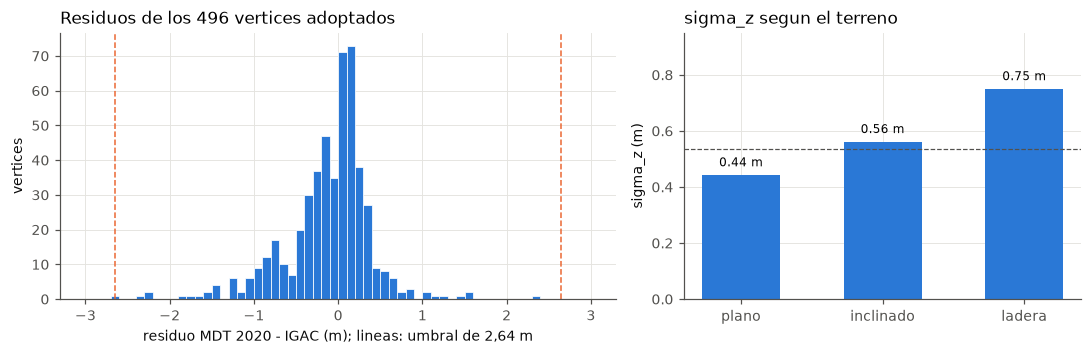

In [30]:
por_zona = v[adoptado].groupby("zona")["residuo_m"].agg(["size", rmse])
for zona, n, s in [("plano (<3 %)", 285, 0.44), ("inclinado (3-8 %)", 130, 0.56), ("ladera (>8 %)", 81, 0.75)]:
    mostrar(f"vertices en {zona}", por_zona.loc[zona, "size"])
    mostrar(f"sigma_z en {zona} (m)", por_zona.loc[zona, "rmse"], 2)
anos = pd.cut(v["ano_calcul"], [0, 1990, 2000, 2010, 3000], labels=["hasta 1990", "1991-2000", "2001-2010", "despues de 2010"])
por_ano = v[adoptado].groupby(anos[adoptado], observed=True)["residuo_m"].agg(rmse)
for grupo, s in zip(por_ano.index, [0.59, 0.51, 0.49, 0.63]):
    mostrar(f"sigma_z {grupo} (m)", por_ano[grupo], 2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.3), gridspec_kw={"width_ratios": [1.4, 1]})
ax1.hist(r, bins=np.arange(-3, 3.01, 0.1), color=AZUL, edgecolor="white", linewidth=0.5)
for x in (-3 * s2, 3 * s2):
    ax1.axvline(x, color=NARANJA, linewidth=1, linestyle="--")
ax1.set_xlabel("residuo MDT 2020 - IGAC (m); lineas: umbral de 2,64 m")
ax1.set_ylabel("vertices")
ax1.set_title(f"Residuos de los {len(r)} vertices adoptados", loc="left")
orden_z = ["plano (<3 %)", "inclinado (3-8 %)", "ladera (>8 %)"]
vals = [por_zona.loc[z_, "rmse"] for z_ in orden_z]
ax2.bar(["plano", "inclinado", "ladera"], vals, color=AZUL, width=0.55)
for i, s_ in enumerate(vals):
    ax2.text(i, s_ + 0.02, f"{s_:.2f} m", ha="center", va="bottom", fontsize=8)
ax2.axhline(rmse(r), color=TINTA_2, linewidth=0.8, linestyle="--")
ax2.set_ylim(0, 0.95)
ax2.set_ylabel("sigma_z (m)")
ax2.set_title("sigma_z segun el terreno", loc="left")
plt.tight_layout()
plt.show()

**Tabla 8.** σz del MDT 2020 por tipo de terreno, con el conjunto oficial y con el de la etapa 1, que es el que se usa solo como sensibilidad. Los valores de la etapa 1 son mayores sobre todo en ladera porque incluyen CD-543 y CD-445, dos vértices de ladera con terreno modificado que se excluyeron en la etapa 2.

In [31]:
filas8 = []
DOC_8 = {"plano (<3 %)": (285, 0.44, 287, 0.79), "inclinado (3-8 %)": (130, 0.56, 131, 0.75),
         "ladera (>8 %)": (81, 0.75, 83, 1.36)}
for zona, (n_a, s_a, n_1, s_1) in DOC_8.items():
    ra = v.loc[adoptado & v["zona"].eq(zona), "residuo_m"]
    r1 = v.loc[bajo1 & v["zona"].eq(zona), "residuo_m"]
    mostrar(f"tabla 8, {zona}: vertices adoptados", len(ra))
    mostrar(f"tabla 8, {zona}: sigma_z adoptado (m)", rmse(ra), 2)
    mostrar(f"tabla 8, {zona}: vertices etapa 1", len(r1))
    mostrar(f"tabla 8, {zona}: sigma_z etapa 1 (m)", rmse(r1), 2)
    filas8.append((zona, len(ra), rmse(ra), len(r1), rmse(r1)))
filas8.append(("todos", adoptado.sum(), rmse(v.loc[adoptado, "residuo_m"]), bajo1.sum(), rmse(v.loc[bajo1, "residuo_m"])))
tabla8 = pd.DataFrame(filas8, columns=["tipo de terreno", "vertices adoptado", "sigma_z adoptado (m)",
                                       "vertices etapa 1", "sigma_z etapa 1 (m)"]).set_index("tipo de terreno")
excl_ladera = sorted(v.loc[bajo1 & ~adoptado & v["zona"].eq("ladera (>8 %)"), "vertice"])
print("Vertices de ladera excluidos en la etapa 2:", excl_ladera)
mostrar("excluidos de ladera en la etapa 2 son CD-445 y CD-543", float(excl_ladera == ["CD-445", "CD-543"]))
mostrar("ladera / plano con el conjunto adoptado", tabla8.iloc[2, 1] / tabla8.iloc[0, 1], 1)
tabla8.round(3)

tabla 8, plano (<3 %): vertices adoptados: 285
tabla 8, plano (<3 %): sigma_z adoptado (m): 0.44
tabla 8, plano (<3 %): vertices etapa 1: 287
tabla 8, plano (<3 %): sigma_z etapa 1 (m): 0.79
tabla 8, inclinado (3-8 %): vertices adoptados: 130
tabla 8, inclinado (3-8 %): sigma_z adoptado (m): 0.56
tabla 8, inclinado (3-8 %): vertices etapa 1: 131
tabla 8, inclinado (3-8 %): sigma_z etapa 1 (m): 0.75
tabla 8, ladera (>8 %): vertices adoptados: 81
tabla 8, ladera (>8 %): sigma_z adoptado (m): 0.75
tabla 8, ladera (>8 %): vertices etapa 1: 83
tabla 8, ladera (>8 %): sigma_z etapa 1 (m): 1.36
Vertices de ladera excluidos en la etapa 2: ['CD-445', 'CD-543']
excluidos de ladera en la etapa 2 son CD-445 y CD-543: 1
ladera / plano con el conjunto adoptado: 1.7


,vertices adoptado,sigma_z adoptado (m),vertices etapa 1,sigma_z etapa 1 (m)
tipo de terreno,,,,
plano (<3 %),285,0.443,287,0.785
inclinado (3-8 %),130,0.562,131,0.753
ladera (>8 %),81,0.751,83,1.364
todos,496,0.536,501,0.900


### 4.3 Correlación espacial del error

Para saber hasta qué distancia los errores del MDT se parecen entre sí, se consultaron sus alturas en una cuadrícula de 41 × 41 puntos separados 5 m, es decir, un cuadro de 200 × 200 m en una zona plana. Antes de analizar los errores se quitó la inclinación general del terreno, para que lo que quedara fuera solo el ruido del modelo y no la forma del relieve. Con esos datos se ajustó un variograma, una curva que muestra cómo cambia la diferencia entre dos puntos a medida que se alejan.

De esa curva sale el **alcance**: La distancia a partir de la cual dos puntos ya no comparten error. Aquí fue de 160,9 m. El cálculo del error de la pendiente usa un tercio de ese valor, **A = 53,6 m**, porque en el modelo exponencial la correlación ya ha caído a cerca del 5 % al llegar al alcance. 

Al final se compara A con la longitud típica de las calles de la red. Esa comparación es de importancia porque en los tramos cortos los dos extremos están tan cerca que comparten buena parte de su error, y es ahí donde tener en cuenta la correlación cambia más el resultado.

In [32]:
corr = pd.read_csv(ARCHIVO_CORRELACION).set_index("modelo")
mostrar("puntos validos de la grilla", corr.loc["Exponential", "puntos_validos"])
mostrar("alcance exponencial r (m)", corr.loc["Exponential", "rango_efectivo_m"], 2)
mostrar("A = r / 3 (m)", corr.loc["Exponential", "parametro_a_m"], 2)
mostrar("desviacion del residuo de la grilla (m)", corr.loc["Exponential", "desv_residuo_m"], 2)
mostrar("alcance gaussiano (m)", corr.loc["Gaussian", "rango_efectivo_m"], 2)
rc = pd.read_csv(RESPALDO / "resumen_correlacion_20261012.csv")
a400 = rc[(rc["ventana_m"] == 400) & (rc["modelo"] == "Exponential")]["escala_para_contrato_m"].iloc[0]
mostrar("A con ventana de 400 m (m)", a400, 2)
mostrar("mediana de longitud de la red (m)", con["longitud_m"].median(), 1)
corr

puntos validos de la grilla: 1,681
alcance exponencial r (m): 160.90
A = r / 3 (m): 53.63
desviacion del residuo de la grilla (m): 0.40
alcance gaussiano (m): 92.88
A con ventana de 400 m (m): 75.30
mediana de longitud de la red (m): 48.1


,rango_efectivo_m,parametro_a_m,ventana_m,espaciado_m,puntos_validos,desv_residuo_m
modelo,,,,,,
Exponential,160.903018,53.634339,200,5,1681,0.399523
Gaussian,92.876281,46.438140,200,5,1681,0.399523


### 4.4 Muestreo adaptativo

**Prueba de pasos** (*aux_prueba_pasos.py*). Para decidir cada cuántos metros medir la altura a lo largo de una calle, se tomaron 200 segmentos de más de 60 m: 100 planos y 100 con pendiente. En cada uno se consultó el MDT cada 5 m, la medición más detallada. Luego, usando solo algunos de esos puntos (uno de cada dos, uno de cada cuatro o uno de cada diez), se simula qué habría pasado midiendo cada 10, 20 y 50 m, sin tener que consultar de nuevo el servicio.

Los dos grupos se comportan diferente. En los segmentos planos, la pendiente acumulada baja a medida que el paso se va alargando. Una calle plana casi no sube ni baja, así que esa acumulada que aparece con pasos cortos no es relieve, es el ruido del MDT, que se va sumando punto tras punto, un paso largo deja menos puntos y, por eso, suma menos ruido.

En los segmentos con pendiente pasa lo contrario, el paso largo salta por encima de subidas y bajadas que sí existen, y se pierde relieve real. Para la medición se cuenta cuántos segmentos pierden más de 0,5 puntos porcentuales de acumulada frente a la medición cada 5 m.

In [33]:
pp = pd.read_csv(RESPALDO / "prueba_pasos_20261012.csv")
mostrar("segmentos de la prueba de pasos", pp["segmento_id"].nunique())
med = pp.groupby(["grupo", "paso_m"])["acumulada_pct"].median()
for paso, valor in [(5, 0.72), (10, 0.62), (20, 0.51), (50, 0.42)]:
    mostrar(f"mediana de la acumulada en planos, paso {paso} m (%)", med[("Plano", paso)], 2)
perdida = pp[pp["grupo"] == "No plano"].groupby("paso_m")["acum_menos_acum5_pp"].apply(lambda s: (s < -0.5).sum())
for paso, n in [(10, 10), (20, 14), (50, 16)]:
    mostrar(f"inclinados que pierden mas de 0,5 pp con paso {paso} m", perdida[paso])
mostrar("maxima perdida de relieve (pp)", -pp["acum_menos_acum5_pp"].min(), 1)

segmentos de la prueba de pasos: 200
mediana de la acumulada en planos, paso 5 m (%): 0.72
mediana de la acumulada en planos, paso 10 m (%): 0.62
mediana de la acumulada en planos, paso 20 m (%): 0.51
mediana de la acumulada en planos, paso 50 m (%): 0.42
inclinados que pierden mas de 0,5 pp con paso 10 m: 10
inclinados que pierden mas de 0,5 pp con paso 20 m: 14
inclinados que pierden mas de 0,5 pp con paso 50 m: 16
maxima perdida de relieve (pp): 9.6


**Piso de ruido y costo.** En una calle plana la acumulada real debería ser cero, pero como cada altura del MDT tiene un pequeño error, al sumar las diferencias entre puntos siempre aparece algo de acumulada. Ese valor, que solo viene del error, es el piso de ruido. Para los segmentos planos se calcula con paso de 10 m y con el de 50 m que se usa con más puntos se suma más ruido. El costo es el número de puntos que habría que consultar al servicio en toda la red con cada paso. Cada segmento lleva un punto cada tantos metros como indique el paso, más el inicial, y nunca menos de dos: n = max(2, int(L / paso) + 1).

In [34]:
planos = con[con["clasificacion_invias"] == "Plano"]
n10 = np.maximum(2, (planos["longitud_m"] / 10).astype(int) + 1)
mostrar("mediana del piso en planos si el paso fuera 10 m (%)", np.median(piso_ruido(planos["longitud_m"], n10)), 2)
mostrar("mediana del piso con el paso de 50 m que se usa (%)", con.loc[con["paso_muestreo_m"] == 50, "ruido_acumulada_pct"].median(), 2)
L = con["longitud_m"]
mostrar("puntos con paso de 10 m en toda la red", np.maximum(2, (L / 10).astype(int) + 1).sum())
mostrar("puntos con paso de 50 m en toda la red", np.maximum(2, (L / 50).astype(int) + 1).sum())

mediana del piso en planos si el paso fuera 10 m (%): 2.39
mediana del piso con el paso de 50 m que se usa (%): 0.93
puntos con paso de 10 m en toda la red: 1,534,424
puntos con paso de 50 m en toda la red: 510,021


Cuántos segmentos quedaron con cada paso, cuántos tienen solo sus dos extremos (en ellos la acumulada es igual a la neta) y el máximo de puntos de un perfil.

In [62]:
pasos = con["paso_muestreo_m"].value_counts()
mostrar("segmentos con paso de 50 m", pasos.get(50.0, 0))
mostrar("segmentos con paso de 10 m", pasos.get(10.0, 0))
dos = con["n_puntos_muestreados"].eq(2)
mostrar("segmentos con solo dos puntos", dos.sum())
mostrar("% con solo dos puntos", 100 * dos.mean(), 2)
mostrar("maximo de puntos en un segmento", con["n_puntos_muestreados"].max())

segmentos con paso de 50 m: 159,803
segmentos con paso de 10 m: 64,527
segmentos con solo dos puntos: 139,715
% con solo dos puntos: 62.28
maximo de puntos en un segmento: 161


### 4.6 Segmentos sin dato en un punto intermedio

Se deja vacía la neta solo cuando falta un extremo. La implementación la deja vacía también cuando falta un punto intermedio, porque la ganancia y la pérdida quedarían incompletas.

In [63]:
falta_extremo = fuera & (df["z_inicio_m"].isna() | df["z_fin_m"].isna())
mostrar("fuera de cobertura por un punto intermedio", (fuera & ~falta_extremo).sum())

fuera de cobertura por un punto intermedio: 6


# 5. Estrategia de evaluación y verificación



### 5.2 Validaciones 

Las 17 reglas del contrato para la unificación correcta con el grafo se ejecuta en el programa principal antes de exportar; su resultado queda en la bitácora y en el manifiesto. Aquí se repiten tres de las más importantes.

In [65]:
neta = con["pendiente_neta_pct"]
d = (neta - 100 * (con["z_fin_m"] - con["z_inicio_m"]) / con["longitud_m"]).abs().max()
mostrar("neta = 100 (z_fin - z_inicio) / L (diferencia < 1e-9)", float(d < 1e-9))
mostrar("acumulada >= |neta| en todos los segmentos", float((con["pendiente_acumulada_pct"] >= con["neta_abs"] - 1e-9).all()))
err = error_pendiente(con["longitud_m"])
mostrar("error_pendiente_pct segun la formula del contrato", float((err - con["error_pendiente_pct"]).abs().max() < 1e-9))
externa("17 validaciones del programa principal", "17 de 17", "bitacora")

neta = 100 (z_fin - z_inicio) / L (diferencia < 1e-9): 1
acumulada >= |neta| en todos los segmentos: 1
error_pendiente_pct segun la formula del contrato: 1
17 validaciones del programa principal: 17 de 17  (fuente: bitacora)


Como verificación del archivo se comprobó, en todos los segmentos, que la pendiente neta coincide con la calculada a partir de sus alturas extremas y su longitud, que la acumulada nunca es menor que el valor absoluto de la neta y que el error de la pendiente es de la fórmula anteriormente mencionada. Además, superó sus 17 validaciones internas.

### 5.4 Valores de σz de la sensibilidad

Los cuatro σz de la sensibilidad corresponden a alternativas. 0,536 m es el adoptado; 0,595 m es el que resultaría si se conservara CD-109A, el excluido con la evidencia, 0,900 m sin la segunda etapa; 1,013 m es el de la muestra sin depurar.

In [66]:
mostrar("sigma_z si CD-109A se conservara (m)", rmse(v.loc[adoptado | v["vertice"].eq("CD-109A"), "residuo_m"]), 3)
mostrar("sigma_z sin la segunda etapa (m)", rmse(v.loc[bajo1, "residuo_m"]), 3)

sigma_z si CD-109A se conservara (m): 0.595
sigma_z sin la segunda etapa (m): 0.900




# 6. Desarrollo técnico



### 6.2 Efecto de cada cambio

A lo largo del trabajo la metodología cambió varias veces, la red vial, el valor de σz, los vértices de validación y la forma de consultar el MDT. Esta sección muestra el efecto que tuvo cada uno de esos cambios. Las cifras de las versiones con OpenStreetMap y archivos que ya no se usan, así que solo se muestran con su fuente. 

In [68]:
sens = pd.read_csv(ARCHIVO_SENSIBILIDAD)
sens["ancho_m"] = sens["ancho_m"].astype(str).str.replace(".0", "", regex=False)
t21 = sens.pivot(index="sigma_z_m", columns="ancho_m", values="pct")[["independencia", "50", "53.6", "75.3", "94.5", "150"]]
mostrar("distinta de cero con sigma_z 1,013 y ancho 53,6 (%)", t21.loc[1.013, "53.6"], 2)
mostrar("distinta de cero con ancho 94,5 y sigma_z 0,536 (%)", t21.loc[0.536, "94.5"], 2)
mostrar("distinta de cero en el archivo final (%)", 100 * con["distinta_de_cero_2sigma"].mean(), 2)
mostrar("diferencia media entre acumulada y neta (pp)", (con["pendiente_acumulada_pct"] - con["neta_abs"]).mean(), 3)
mostrar("filas con pendiente extrema", len(ext))
externa("red OSM de la primera version", "152.560 tramos", "version del comienzo sobre OSM")
externa("tramos confiables en OSM", "de 56,8 % a 35,9 %", "versiones con sigma_z 0,20 y 0,538 m")
externa("distinta de cero con sigma_z 0,538 m", "33,32 %", "version intermedia ")
externa("filas afectadas por el manejo de NaN", "3.949", "diagnostico_nan_invias.py")

distinta de cero con sigma_z 1,013 y ancho 53,6 (%): 23.73
distinta de cero con ancho 94,5 y sigma_z 0,536 (%): 33.68
distinta de cero en el archivo final (%): 31.32
diferencia media entre acumulada y neta (pp): 0.112
filas con pendiente extrema: 2,641
red OSM de la primera version: 152.560 tramos  (fuente: version del comienzo sobre OSM)
tramos confiables en OSM: de 56,8 % a 35,9 %  (fuente: versiones con sigma_z 0,20 y 0,538 m)
distinta de cero con sigma_z 0,538 m: 33,32 %  (fuente: version intermedia )
filas afectadas por el manejo de NaN: 3.949  (fuente: diagnostico_nan_invias.py)


El cambio con más peso fue el de σz, con el valor de la muestra de antes sin depurar, 1,013 m, apenas el 23,73 % de los segmentos tendría una pendiente que se pueda distinguir del error del modelo. Con el valor final, 0,536 m, esa proporción sube a 31,32 %. Es decir, depurar de forma correcta los vértices del IGAC cambió en casi ocho puntos lo que se puede afirmar de la red.

El ancho de correlación también se corrigió,. Al principio se usó 94,5 m. Con él, el 33,68 % de los segmentos parecía distinguible de cero, con el ancho correcto, 53,6 m, son el 31,32 %. El valor inicial mostraba un panorama más bueno de lo que los datos permiten.

El muestreo cada 50 m en las calles planas y cada 10 m en las demás permite calcular la acumulada sin que el ruido la infle, en promedio, la acumulada supera a la neta en apenas 0,112 puntos porcentuales.

**Los 52 casos más altos y el caso 53.** Se ordenan los tramos físicos extremos por su neta y se ve que ninguno de los recuperados desplaza a los 52 revisados.

In [41]:
top = ext.sort_values("neta_abs", ascending=False).drop_duplicates("tramo_fisico")
mostrar("neta del caso 1 (%)", top["neta_abs"].iloc[0], 1)
mostrar("neta del caso 52 (%)", top["neta_abs"].iloc[51], 1)
mostrar("neta del caso 53 (%)", top["neta_abs"].iloc[52], 1)

neta del caso 1 (%): 105.3
neta del caso 52 (%): 67.4
neta del caso 53 (%): 67.1


### 6.3 Acumulada bajo el piso de ruido

Si la acumulada de un segmento no supera su piso de ruido, la diferencia entre acumulada y neta puede deberse al error del MDT.

In [70]:
bajo_piso = con["pendiente_acumulada_pct"] <= con["ruido_acumulada_pct"]
mostrar("segmentos con la acumulada bajo el piso", bajo_piso.sum())
mostrar("% de los segmentos con dato", 100 * bajo_piso.mean(), 1)

segmentos con la acumulada bajo el piso: 124,823
% de los segmentos con dato: 55.6


In [71]:
# Segmentos con la acumulada bajo el piso de ruido, por clase INVIAS
por_clase = pd.DataFrame({
    "segmentos bajo el piso": bajo_piso.groupby(con["clasificacion_invias"]).sum(),
    "% de su clase": 100 * bajo_piso.groupby(con["clasificacion_invias"]).mean(),
    "% del total bajo el piso": 100 * bajo_piso.groupby(con["clasificacion_invias"]).sum() / bajo_piso.sum(),
})
por_clase.round(1)

,segmentos bajo el piso,% de su clase,% del total bajo el piso
clasificacion_invias,,,
Escarpado,0,0.0,0.0
Montañoso,0,0.0,0.0
Ondulado,49,0.3,0.0
Plano,124774,78.1,100.0


En 124.823 segmentos, el 55,6 %, la pendiente acumulada no supera el piso de ruido, es decir, la acumulada que el error del MDT produciría por sí solo. Por lo cuál todos son planos, 124.774 de ellos pertenecen a esa clase, lo que equivale al 78,1 % de los segmentos planos, y solo 49 son ondulados. En los montañosos y escarpados ningún segmento queda bajo el piso. Esto significa que en las calles planas la diferencia entre acumulada y neta es en la mayoría de los casos el ruido del modelo y la neta es la medida más confiable, mientras que en las calles con pendiente la acumulada sí registra subidas y bajadas.

# 7. Resultados, análisis y validación



### 7.1 Cobertura

Segmentos por sentido, con dato y fuera de cobertura. Los fuera de cobertura se separan entre los que no tienen un extremo y los que no tienen un punto intermedio

In [72]:
mostrar("segmentos FT", (df["sentido"] == "FT").sum())
mostrar("segmentos TF", (df["sentido"] == "TF").sum())
mostrar("% con dato", 100 * len(con) / len(df), 2)
mostrar("fuera de cobertura", fuera.sum())
mostrar("fuera por falta de un extremo", falta_extremo.sum())

segmentos FT: 113,850
segmentos TF: 111,854
% con dato: 99.39
fuera de cobertura: 1,374
fuera por falta de un extremo: 1,368


Los 1.374 segmentos sin altura completa no se eliminan, quedan marcados como fuera de cobertura y sin pendiente. El módulo del grafo estima las alturas de esas esquinas a partir de sus vecinas para poder rutear, con un error mayor que en el resto de la red.

### 7.2 Distribución de la pendiente


Se describe cómo se reparte la pendiente acumulada en la red y entre qué longitudes se mueven los segmentos. Después se responde, ¿en cuántas calles la pendiente medida es real y no un efecto del error del MDT? Una pendiente se considera distinguible de cero cuando su valor absoluto supera dos veces su error (|neta| > 2 × error). En esos segmentos el error del modelo no alcanza a explicar la inclinación que se mide, así que se afirma que la calle sube o baja. El conteo se hace por separado para cada clase INVIAS, porque en las calles planas la pendiente es tan pequeña que queda dentro del error, mientras que en las empinadas ocurre lo contrario.

In [73]:
acu = con["pendiente_acumulada_pct"]
mostrar("media de la acumulada (%)", acu.mean(), 2)
mostrar("mediana de la acumulada (%)", acu.median(), 2)
mostrar("percentil 95 de la acumulada (%)", acu.quantile(0.95), 2)
mostrar("longitud minima (m)", con["longitud_m"].min(), 2)
mostrar("longitud maxima (m)", con["longitud_m"].max(), 1)

media de la acumulada (%): 4.26
mediana de la acumulada (%): 0.78
percentil 95 de la acumulada (%): 19.89
longitud minima (m): 2.01
longitud maxima (m): 1,819.2


La pendiente acumulada tiene una mediana de 0,78 % y una media de 4,26 %. Esa diferencia muestra una distribución muy diferente, la mayoría de los segmentos son planos y un grupo pequeño de calles empinadas eleva el promedio. Solo el 5 % de los segmentos supera una acumulada de 19,89 %. La mediana de la acumulada es casi igual a la de la pendiente neta (0,76 %), lo que confirma que en buena parte de la red las dos medidas coinciden. Los segmentos van de 2,01 m a 1.819,2 m de longitud, esta variedad importa porque en los tramos más cortos el error de la pendiente es mayor.

**Tabla 9.** Clasificación INVIAS y pendiente distinguible de cero.

In [75]:
t16 = con.groupby("clasificacion_invias").agg(segmentos=("segmento_id", "size"), distinta=("distinta_de_cero_2sigma", "sum")).reindex(CLASES)
t16["porcentaje"] = 100 * t16["segmentos"] / len(con)
t16["pct_de_la_clase"] = 100 * t16["distinta"] / t16["segmentos"]
t16.loc["Total con dato"] = [len(con), con["distinta_de_cero_2sigma"].sum(), 100, 100 * con["distinta_de_cero_2sigma"].mean()]
for clase, d_, p_ in [("Plano", 8395, 5.3), ("Ondulado", 14260, 85.0), ("Montañoso", 8081, 98.6), ("Escarpado", 39527, 99.95), ("Total con dato", 70263, 31.32)]:
    mostrar(f"{clase}: distinta de cero", t16.loc[clase, "distinta"])
    mostrar(f"{clase}: % de la clase", t16.loc[clase, "pct_de_la_clase"], 2 if clase in ("Escarpado", "Total con dato") else 1)
t16.round(2)

Plano: distinta de cero: 8,395
Plano: % de la clase: 5.3
Ondulado: distinta de cero: 14,260
Ondulado: % de la clase: 85.0
Montañoso: distinta de cero: 8,081
Montañoso: % de la clase: 98.6
Escarpado: distinta de cero: 39,527
Escarpado: % de la clase: 99.95
Total con dato: distinta de cero: 70,263
Total con dato: % de la clase: 31.32


,segmentos,distinta,porcentaje,pct_de_la_clase
clasificacion_invias,,,,
Plano,159803.0,8395.0,71.24,5.25
Ondulado,16785.0,14260.0,7.48,84.96
Montañoso,8194.0,8081.0,3.65,98.62
Escarpado,39548.0,39527.0,17.63,99.95
Total con dato,224330.0,70263.0,100.00,31.32


El 31,32 % de los segmentos con dato tiene una pendiente distinguible de cero, es decir, mayor que dos veces su error. Esa cifra cambia según el tipo de terreno, en los planos, que son el 71,2 % de la red, solo el 5,25 % es distinguible, porque su inclinación real es menor que el error del MDT. 

En cambio, el 84,96 % de los ondulados, el 98,62 % de los montañosos y el 99% de los escarpados. El porcentaje total es bajo porque la mayor parte de Bogotá es plana, en las calles donde la pendiente sí afecta el consumo, el MDT la mide con confianza.

### 7.3 Error y piso de ruido en el archivo

Se describe cuánto error tiene la pendiente en la red. Se muestra el error típico (la mediana) y el mayor de todos. Luego, la mediana de ρ, que indica cuánto se parecen los errores de los dos extremos de un segmento, cuanto más cerca de 1, más se cancelan al restar las alturas.

Después se compara el error según cuántos puntos tiene cada segmento, los segmentos con más puntos son los más largos, y es la longitud la que hace bajar el error, no el número de puntos.

Por último se muestra el piso de ruido con cada paso de muestreo, es decir, cuánta acumulada aparece solo por el error del MDT cuando se mide cada 10 m y cuando se mide cada 50 m.

In [76]:
mostrar("mediana del error (pp)", con["error_pendiente_pct"].median(), 2)
mostrar("maximo del error (pp)", con["error_pendiente_pct"].max(), 2)
mostrar("mediana de rho", con["rho_correlacion"].median(), 3)
grupos = pd.cut(con["n_puntos_muestreados"], [1, 2, 5, 10, 20, np.inf], labels=["2", "3 a 5", "6 a 10", "11 a 20", "mas de 20"])
media_error = con.groupby(grupos, observed=True)["error_pendiente_pct"].mean()
for g, valor in zip(media_error.index, [1.51, 1.12, 0.89, 0.56, 0.21]):
    mostrar(f"error medio con {g} puntos (pp)", media_error[g], 2)
ruido = con.groupby("paso_muestreo_m")["ruido_acumulada_pct"].median()
mostrar("mediana del piso, paso 10 m (%)", ruido[10.0], 2)
mostrar("mediana del piso, paso 50 m (%)", ruido[50.0], 2)

mediana del error (pp): 1.21
maximo del error (pp): 7.23
mediana de rho: 0.408
error medio con 2 puntos (pp): 1.51
error medio con 3 a 5 puntos (pp): 1.12
error medio con 6 a 10 puntos (pp): 0.89
error medio con 11 a 20 puntos (pp): 0.56
error medio con mas de 20 puntos (pp): 0.21
mediana del piso, paso 10 m (%): 2.36
mediana del piso, paso 50 m (%): 0.93


### 7.4 Pendientes extremas

Un segmento es extremo si su neta o su acumulada, supera 35 %. Se separan los que lo son por la neta de los que lo son solo por la acumulada, y se identifica el caso con neta moderada y acumulada más alta.

In [77]:
mostrar("% de los segmentos con dato", 100 * len(ext) / len(con), 2)
mostrar("extremas por la neta", (ext["neta_abs"] > 35).sum())
mostrar("extremas solo por la acumulada", (ext["neta_abs"] <= 35).sum())
caso = om.loc[om["pendiente_acumulada_pct"].idxmax()]
mostrar("neta del caso con acumulada de 69,84 % (%)", abs(caso["pendiente_neta_pct"]), 2)

% de los segmentos con dato: 1.18
extremas por la neta: 2,563
extremas solo por la acumulada: 78
neta del caso con acumulada de 69,84 % (%): 7.66


 2.641 segmentos con pendiente extrema, el 1,18 % de los que tienen dato. En 2.563 de ellos es la pendiente neta la que supera el 35 %, mientras que en los 78 restantes solo lo hace la acumulada. 
 
 Estos últimos corresponden a perfiles que suben y bajan dentro del mismo tramo. El caso más marcado tiene una neta de apenas 7,66 % y una acumulada de 69,84 %, la calle casi no cambia de altura entre sus extremos, pero registra fuertes subidas y bajadas.

 El caso más marcado, con una neta de 7,66 % y una acumulada de 69,84 %, se revisó en Google Maps: el tramo está en una zona natural, sin una calle visible, como una gran parte de los casos extremos revisados.

### 7.4.1 Puentes y túneles

El MDT mide el terreno y no las estructuras, sobre un puente mide lo que hay debajo y en un túnel mide lo de encima, así que en esos tramos la pendiente puede salir extrema sin serlo. Como la Malla Vial no indica, se identificaron con OpenStreetMap (aux_puentes_tuneles_osm.py). Un segmento se marca cuando al menos la mitad de su longitud queda a menos de 8 m de una vía que OpenStreetMap etiqueta como puente o túnel y además va en la misma dirección, lo que evita marcar la calle que pasa por debajo. Para comprobar que el resultado no depende del margen de 8 m, el cruce se repite con 5 y con 15 m.

In [79]:
if (AUX / "puentes_tuneles_sensibilidad.csv").exists():
    sp = leer(AUX / "puentes_tuneles_sensibilidad.csv").set_index("buffer_m")
    ef = leer(AUX / "puentes_tuneles_resumen.csv").set_index("conjunto")
    sg = leer(AUX / "puentes_tuneles_segmentos.csv")
    if (AUX / "osm_puentes_tuneles_bogota.gpkg").exists():
        mostrar("vias de OSM con puente o tunel", len(gpd.read_file(AUX / "osm_puentes_tuneles_bogota.gpkg")))
    mostrar("segmentos marcados (8 m)", sp.loc[8.0, "segmentos_marcados"])
    mostrar("sobre puente", verdadero(sg["puente_osm"]).sum())
    mostrar("en tunel", verdadero(sg["tunel_osm"]).sum())
    mostrar("filas extremas marcadas", sp.loc[8.0, "extremas_marcadas"])
    mostrar("tramos extremos marcados", sp.loc[8.0, "tramos_extremos_marcados"])
    mostrar("% de los 1.328 tramos extremos", 100 * sp.loc[8.0, "tramos_extremos_marcados"] / 1328, 1)
    mostrar("marcados con 5 m", sp.loc[5.0, "segmentos_marcados"])
    mostrar("marcados con 15 m", sp.loc[15.0, "segmentos_marcados"])
    mostrar("Plano sin puentes ni tuneles (%)", ef.loc["sin puentes ni tuneles OSM", "plano_pct"], 2)
    mostrar("extremas sin puentes ni tuneles (%)", ef.loc["sin puentes ni tuneles OSM", "extremas_pct"], 2)
    mostrar("planos entre los segmentos sobre puente o tunel (%)", ef.loc["solo puentes y tuneles OSM", "plano_pct"])
    display(sp)
else:
    print("Faltan los resultados de aux_puentes_tuneles_osm.py en datos_salida/auxiliares.")

vias de OSM con puente o tunel: 3,007
segmentos marcados (8 m): 985
sobre puente: 817
en tunel: 170
filas extremas marcadas: 6
tramos extremos marcados: 4
% de los 1.328 tramos extremos: 0.3
marcados con 5 m: 768
marcados con 15 m: 1,451
Plano sin puentes ni tuneles (%): 71.22
extremas sin puentes ni tuneles (%): 1.18
planos entre los segmentos sobre puente o tunel (%): 75


,segmentos_marcados,extremas_marcadas,tramos_extremos_marcados
buffer_m,,,
5.0,768,6,4
8.0,985,6,4
15.0,1451,6,4


Para descartar que las pendientes extremas se deban a puentes o túneles, que el MDT no representa como la vía, los segmentos de la Malla Vial se cruzaron con las 3.007 vías que OpenStreetMap etiqueta como puente o túnel. Con un margen de 8 m se marcaron 985 segmentos, de los cuales solo 6 tienen pendiente extrema, correspondientes a 4 tramos físicos, el 0,3 % de los 1.328 tramos extremos. El resultado no depende del margen, con 5 y con 15 m el número de segmentos marcados varía entre 768 y 1.451, pero las filas extremas siguen siendo 6. Además, el 75 % de los segmentos sobre puente o túnel son planos, de modo que en la mayoría de estas estructuras el MDT no produce pendientes anómalas. Las pendientes extremas de Bogotá se explican por las laderas y no por los puentes

### 7.5 Revisión visual de los 52 casos más altos

Los 52 tramos físicos con mayor neta se revisaron en Google Maps. Se cuentan las categorías, los que caen sobre vegetación según la observación, la clase de vía, el CIV y la longitud.

**Tabla 10.** Resultado de la revisión visual de los 52 tramos con mayor pendiente.

In [50]:
rev = pd.read_csv(RESPALDO / "revision_visual_52_anotada.csv")
rev["se_ve"] = rev["se_ve"].astype(str).str.strip()
t17 = rev["se_ve"].value_counts().reindex(["No_se_ve", "Calle_normal", "Calle_abierta", "Escalera"]).fillna(0).astype(int).to_frame("casos")
t17["porcentaje"] = 100 * t17["casos"] / len(rev)
for c, n in [("No_se_ve", 36), ("Calle_normal", 9), ("Calle_abierta", 7), ("Escalera", 0)]:
    mostrar(f"{c}", t17.loc[c, "casos"])
veg = rev["se_ve"].eq("No_se_ve") & rev["observacion"].fillna("").str.contains("vegeta|verde|monte", case=False)
mostrar("no se ve y cae sobre vegetacion", veg.sum())
sd = rev["highway"].eq("sin_definir")
mostrar("clase Sin definir, todos en no se ve", float((sd.sum() == 10) and rev.loc[sd, "se_ve"].eq("No_se_ve").all()))
mostrar("casos con CIV igual a cero", rev["civ"].eq(0).sum())
mostrar("casos con solo dos puntos", rev["n_puntos_muestreados"].eq(2).sum())
mostrar("mediana de longitud (m)", rev["longitud_m"].median(), 1)
loc_rev = rev["localidad"].map(sin_tildes)
mostrar("calles normales en Rafael Uribe Uribe", (rev["se_ve"].eq("Calle_normal") & loc_rev.eq("RAFAEL URIBE URIBE")).sum())
mostrar("calles abiertas en Ciudad Bolivar", (rev["se_ve"].eq("Calle_abierta") & loc_rev.eq("CIUDAD BOLIVAR")).sum())
t17.round(1)

No_se_ve: 36
Calle_normal: 9
Calle_abierta: 7
Escalera: 0
no se ve y cae sobre vegetacion: 29
clase Sin definir, todos en no se ve: 1
casos con CIV igual a cero: 11
casos con solo dos puntos: 28
mediana de longitud (m): 19.4
calles normales en Rafael Uribe Uribe: 7
calles abiertas en Ciudad Bolivar: 5


,casos,porcentaje
se_ve,,
No_se_ve,36,69.2
Calle_normal,9,17.3
Calle_abierta,7,13.5
Escalera,0,0.0


### 7.5.1 Revisión de la franja de 35 a 50 %

El 35 % es una cota, no un detector de errores: por encima de la calle más empinada registrada (34,8 %) una pendiente es poco plausible, pero no necesariamente falsa. Las dos revisiones muestran en qué proporción los tramos marcados son calles reales, vías no visibles o escaleras, y esa proporción cambia con la magnitud.

La franja de 35 a 50 % tiene la mayoría de las filas extremas y no estaba representada en los 52 casos. Se revisó una muestra aleatoria de 50 tramos físicos. El intervalo al 95 % indica el rango en que probablemente está la proporción, dado que se observan 50.

**Tabla 11.** Resultado de la revisión visual de la franja de 35 a 50 %.

In [80]:
franja = ext[(ext["neta_abs"] > 35) & (ext["neta_abs"] <= 50)]
tramos_f = top[(top["neta_abs"] > 35) & (top["neta_abs"] <= 50)]
mostrar("filas extremas entre 35 y 50 %", len(franja))
mostrar("% de las filas extremas", 100 * len(franja) / len(ext), 1)
mostrar("tramos fisicos de la franja", len(tramos_f))
if (AUX / "muestra_extremas_35_50.csv").exists():
    mu = leer(AUX / "muestra_extremas_35_50.csv")
    mu["se_ve"] = mu["se_ve"].astype(str).str.strip()
    n = len(mu)
    filas = []
    for cat, k_doc, ic in [("Calle_normal", 21, (29, 56)), ("Calle_abierta", 10, (11, 33)),
                           ("No_se_ve", 15, (19, 44)), ("Escalera", 4, (3, 19))]:
        k = int(mu["se_ve"].eq(cat).sum())
        lo, hi = wilson(k, n)
        mostrar(f"{cat}: casos", k)
        mostrar(f"{cat}: intervalo inferior (%)", lo)
        mostrar(f"{cat}: intervalo superior (%)", hi)
        filas.append((cat, k, 100 * k / n, lo, hi))
    reales = int(mu["se_ve"].isin(["Calle_normal", "Calle_abierta"]).sum())
    lo, hi = wilson(reales, n)
    mostrar("calles reales (%)", 100 * reales / n)
    mostrar("calles reales: intervalo", float(round(lo) == 48 and round(hi) == 74))
    civ0 = mu[mu["civ"] == 0]
    mostrar("casos con CIV igual a cero", len(civ0))
    mostrar("CIV cero que son calle pavimentada", civ0["se_ve"].eq("Calle_normal").sum())
    t18 = pd.DataFrame(filas, columns=["categoria", "casos", "porcentaje", "ic95_inferior", "ic95_superior"]).set_index("categoria")
    t18["franja_mayor_67_pct"] = [17.3, 13.5, 69.2, 0]
    display(t18.round(1))
else:
    print("Falta la muestra anotada en datos_salida/auxiliares.")

filas extremas entre 35 y 50 %: 1,902
% de las filas extremas: 72.0
tramos fisicos de la franja: 956
Calle_normal: casos: 21
Calle_normal: intervalo inferior (%): 29
Calle_normal: intervalo superior (%): 56
Calle_abierta: casos: 10
Calle_abierta: intervalo inferior (%): 11
Calle_abierta: intervalo superior (%): 33
No_se_ve: casos: 15
No_se_ve: intervalo inferior (%): 19
No_se_ve: intervalo superior (%): 44
Escalera: casos: 4
Escalera: intervalo inferior (%): 3
Escalera: intervalo superior (%): 19
calles reales (%): 62
calles reales: intervalo: 1
casos con CIV igual a cero: 6
CIV cero que son calle pavimentada: 0


,casos,porcentaje,ic95_inferior,ic95_superior,franja_mayor_67_pct
categoria,,,,,
Calle_normal,21,42.0,29.4,55.8,17.3
Calle_abierta,10,20.0,11.2,33.0,13.5
No_se_ve,15,30.0,19.1,43.8,69.2
Escalera,4,8.0,3.2,18.8,0.0


De 35 a 50 % reúne el 72,0 % de las filas con pendiente extrema (1.902 de 2.641, en 956 tramos físicos), por lo que se revisó aparte una muestra aleatoria de 50 tramos. El 62 % corresponde a calles reales (intervalo de 48 a 74 %), 42 % calles normales y 20 % abiertas sin pavimentar. En el 30 % no se ve una calle y el 8 % son escaleras. El contraste con los 52 tramos más empinados, donde el 69,2 % no mostraba una calle, indica, la proporción de vías reales disminuye a medida que aumenta la pendiente. Por eso el 35 % funciona como una cota.


### 7.6 Efecto de la resolución del modelo de elevación

¿Cambiaría mucho la pendiente si se usara otro modelo de elevación? 

Se toman 4.000 segmentos, 1.000 de cada clase INVIAS, y se calcula su pendiente neta con tres fuentes, el MDT 2020, el MDT 2025, y SRTM, un modelo global gratuito de 30 m de resolución. Las cifras para toda la ciudad se ponderan según el peso real de cada clase en la red. Los resultados son diferencias frente al MDT 2020, muestran cuánto se aleja cada modelo del que se adoptó, no cuánto se aleja del terreno real.

**Pendiente neta del MDT 2025 y de SRTM frente a la del MDT 2020.**

In [81]:
if (AUX / "resolucion_resumen.csv").exists():
    rr = leer(AUX / "resolucion_resumen.csv")
    rr["modelo"] = rr["modelo"].astype(str)

    def val(modelo, grupo, col):
        f = rr[(rr["modelo"] == modelo) & (rr["valor_grupo"].astype(str).map(sin_tildes) == sin_tildes(grupo))]
        return f[col].iloc[0]

    filas = [("RMSE de la pendiente, toda la ciudad (pp)", "ponderado por clase", "rmse_pp", 2, 2.02, 5.15),
             ("Correlacion de la pendiente, toda la ciudad", "ponderado por clase", "correlacion", 2, 0.97, 0.80),
             ("Misma clase INVIAS, toda la ciudad (%)", "ponderado por clase", "misma_clase_invias_pct", 1, 91.0, 65.9),
             ("RMSE en terreno plano (pp)", "Plano", "rmse_pp", 2, 1.68, 3.77),
             ("Correlacion en terreno plano", "Plano", "correlacion", 2, 0.45, 0.16),
             ("Pendiente exactamente nula en terreno plano (%)", "Plano", "neta_exactamente_cero_pct", 1, 65.8, 28.2),
             ("RMSE en tramos de menos de 20 m (pp)", "< 20 m", "rmse_pp", 2, 4.61, 8.91),
             ("RMSE en tramos de mas de 100 m (pp)", "> 100 m", "rmse_pp", 2, 0.63, 2.57),
             ("Extremas en terreno escarpado (%)", "Escarpado", "extrema_mayor_35_pct", 1, 6.6, 3.4)]
    t19 = []
    for nombre, grupo, col, dec, d25, dsr in filas:
        a25, asr = val("2025", grupo, col), val("srtm", grupo, col)
        mostrar(f"{nombre}, MDT 2025", a25, dec)
        mostrar(f"{nombre}, SRTM", asr, dec)
        t19.append((nombre, a25, asr))
    mostrar("extremas en escarpado con el MDT 2020 (%)", val("2025", "Escarpado", "extrema_mayor_35_pct_2020"), 1)
    if (AUX / "resolucion_segmentos.csv").exists():
        rs = leer(AUX / "resolucion_segmentos.csv")
        mostrar("segmentos de la muestra", len(rs))
        for col, media, r_doc, nombre in [("dz_ini_2025_m", 0.13, 1.68, "MDT 2025"), ("dz_ini_srtm_m", 1.90, 4.10, "SRTM")]:
            mostrar(f"{nombre}: diferencia media de elevacion (m)", rs[col].mean(), 2)
            mostrar(f"{nombre}: RMSE de elevacion (m)", rmse(rs[col]), 2)
    display(pd.DataFrame(t19, columns=["medida", "MDT 2025", "SRTM 30 m"]).set_index("medida").round(2))
else:
    print("Faltan los resultados de aux_resolucion_2020_2025_srtm.py en datos_salida/auxiliares.")

RMSE de la pendiente, toda la ciudad (pp), MDT 2025: 2.02
RMSE de la pendiente, toda la ciudad (pp), SRTM: 5.15
Correlacion de la pendiente, toda la ciudad, MDT 2025: 0.97
Correlacion de la pendiente, toda la ciudad, SRTM: 0.80
Misma clase INVIAS, toda la ciudad (%), MDT 2025: 91.0
Misma clase INVIAS, toda la ciudad (%), SRTM: 65.9
RMSE en terreno plano (pp), MDT 2025: 1.68
RMSE en terreno plano (pp), SRTM: 3.77
Correlacion en terreno plano, MDT 2025: 0.45
Correlacion en terreno plano, SRTM: 0.16
Pendiente exactamente nula en terreno plano (%), MDT 2025: 65.8
Pendiente exactamente nula en terreno plano (%), SRTM: 28.2
RMSE en tramos de menos de 20 m (pp), MDT 2025: 4.61
RMSE en tramos de menos de 20 m (pp), SRTM: 8.91
RMSE en tramos de mas de 100 m (pp), MDT 2025: 0.63
RMSE en tramos de mas de 100 m (pp), SRTM: 2.57
Extremas en terreno escarpado (%), MDT 2025: 6.6
Extremas en terreno escarpado (%), SRTM: 3.4
extremas en escarpado con el MDT 2020 (%): 6.4
segmentos de la muestra: 4,000


,MDT 2025,SRTM 30 m
medida,,
"RMSE de la pendiente, toda la ciudad (pp)",2.02,5.15
"Correlacion de la pendiente, toda la ciudad",0.97,0.80
"Misma clase INVIAS, toda la ciudad (%)",90.96,65.86
RMSE en terreno plano (pp),1.68,3.77
Correlacion en terreno plano,0.45,0.16
Pendiente exactamente nula en terreno plano (%),65.83,28.20
RMSE en tramos de menos de 20 m (pp),4.61,8.91
RMSE en tramos de mas de 100 m (pp),0.63,2.57
Extremas en terreno escarpado (%),6.63,3.40


Se compara la pendiente neta de 4.000 segmentos con el MDT 2020, el MDT 2025 y SRTM, un modelo global de 30 m. El MDT 2025 se parece al de 2020, su correlación es de 0,97, la diferencia típica es de 2,02 puntos porcentuales y el 91 % de los segmentos queda en la misma clase INVIAS. Sin embargo, por tener sus alturas redondeadas a metro entero, asigna una pendiente exactamente nula al 65,8 % de los segmentos planos. SRTM se aleja, la diferencia típica sube a 5,15 puntos, la correlación baja a 0,80. Además, suaviza las laderas, en terreno escarpado solo marca como extremos el 3,4 % de los segmentos, frente al 6,4 % del MDT 2020. Las diferencias son más grandes en los tramos cortos, donde un segmento de menos de 20 m puede caer dentro de un mismo píxel de SRTM.

In [82]:
for sector, (n, rs_, rc_) in {"plano": (324, 3.12, 3.49), "cerros": (109, 6.53, 4.69)}.items():
    b = pd.read_csv(RESPALDO / f"comparacion_30m_{sector}_20260921.csv")
    for col, rm_doc, nombre in [("pendiente_srtm_pct", rs_, "SRTM"), ("pendiente_cop30_pct", rc_, "GLO-30")]:
        k = b.dropna(subset=["pendiente_lidar_pct", col])
        mostrar(f"{sector}: tramos con {nombre}", len(k))
        mostrar(f"{sector}: RMSE {nombre} (pp)", np.sqrt(((k["pendiente_lidar_pct"] - k[col]) ** 2).mean()), 2)

plano: tramos con SRTM: 324
plano: RMSE SRTM (pp): 3.12
plano: tramos con GLO-30: 324
plano: RMSE GLO-30 (pp): 3.49
cerros: tramos con SRTM: 109
cerros: RMSE SRTM (pp): 6.53
cerros: tramos con GLO-30: 109
cerros: RMSE GLO-30 (pp): 4.69


# 8. Evaluación y validación



### 8.1 Exactitud vertical y MDT 2025

Los residuos de los dos MDT en los mismos vértices están correlacionados

Una parte del residuo viene del vértice y no del modelo. Sin 10-E-1, cuya altura publicada es errónea, la correlación baja.

In [83]:
mostrar("correlacion de residuos 2020 y 2025", m25["dif_2020_m"].corr(m25["dif_2025_m"]), 2)
s10 = m25[m25["vertice"] != "10-E-1"]
mostrar("correlacion sin 10-E-1", s10["dif_2020_m"].corr(s10["dif_2025_m"]), 2)

correlacion de residuos 2020 y 2025: 0.83
correlacion sin 10-E-1: 0.60


### 8.2 Rescate de segmentos

In [84]:
externa("puntos nuevos consultados para completar perfiles", "409", "corrida de cierre")

puntos nuevos consultados para completar perfiles: 409  (fuente: corrida de cierre)


### 8.3 Sensibilidad a σz y al ancho

Se recalcula el porcentaje de segmentos con pendiente distinguible de cero para cuatro σz y seis anchos.

**Tabla 12** Porcentaje de segmentos con pendiente distinta de cero según σz y ancho de correlación.

In [86]:
DOC_21 = {0.536: [27.57, 31.06, 31.32, 32.66, 33.68, 36.24], 0.595: [26.22, 29.78, 30.02, 31.34, 32.32, 34.68],
          0.900: [21.01, 24.86, 25.10, 26.43, 27.38, 29.41], 1.013: [19.48, 23.47, 23.73, 25.00, 26.01, 28.07]}
for s, fila in DOC_21.items():
    for col, valor in zip(t21.columns, fila):
        mostrar(f"sigma_z {s} y ancho {col}", t21.loc[s, col], 2)
an, Lc = con["neta_abs"].to_numpy(), con["longitud_m"].to_numpy()
err_g = 100 * np.sqrt(2 * SIGMA_Z ** 2 * (1 - np.exp(-(Lc / (94.5 / 2)) ** 2))) / Lc
mostrar("gaussiano con alcance de 94,5 m (%)", 100 * (an > 2 * err_g).mean(), 2)
mostrar("aumento de 53,6 a 75,3 m (pp)", t21.loc[0.536, "75.3"] - t21.loc[0.536, "53.6"], 2)
mostrar("aumento de 53,6 a 94,5 m (pp)", t21.loc[0.536, "94.5"] - t21.loc[0.536, "53.6"], 2)
t21

sigma_z 0.536 y ancho independencia: 27.57
sigma_z 0.536 y ancho 50: 31.06
sigma_z 0.536 y ancho 53.6: 31.32
sigma_z 0.536 y ancho 75.3: 32.66
sigma_z 0.536 y ancho 94.5: 33.68
sigma_z 0.536 y ancho 150: 36.24
sigma_z 0.595 y ancho independencia: 26.22
sigma_z 0.595 y ancho 50: 29.78
sigma_z 0.595 y ancho 53.6: 30.02
sigma_z 0.595 y ancho 75.3: 31.34
sigma_z 0.595 y ancho 94.5: 32.32
sigma_z 0.595 y ancho 150: 34.68
sigma_z 0.9 y ancho independencia: 21.01
sigma_z 0.9 y ancho 50: 24.86
sigma_z 0.9 y ancho 53.6: 25.10
sigma_z 0.9 y ancho 75.3: 26.43
sigma_z 0.9 y ancho 94.5: 27.38
sigma_z 0.9 y ancho 150: 29.41
sigma_z 1.013 y ancho independencia: 19.48
sigma_z 1.013 y ancho 50: 23.47
sigma_z 1.013 y ancho 53.6: 23.73
sigma_z 1.013 y ancho 75.3: 25.00
sigma_z 1.013 y ancho 94.5: 26.01
sigma_z 1.013 y ancho 150: 28.07
gaussiano con alcance de 94,5 m (%): 32.09
aumento de 53,6 a 75,3 m (pp): 1.34
aumento de 53,6 a 94,5 m (pp): 2.36


ancho_m,independencia,50,53.6,75.3,94.5,150
sigma_z_m,,,,,,
0.536,27.57,31.06,31.32,32.66,33.68,36.24
0.595,26.22,29.78,30.02,31.34,32.32,34.68
0.900,21.01,24.86,25.10,26.43,27.38,29.41
1.013,19.48,23.47,23.73,25.00,26.01,28.07


### 8.4 Sensibilidad con un σz por tipo de terreno

Como el error es mayor en ladera, se recalcula el error de cada segmento con el σz de su clase INVIAS: 0,44 m en los planos, 0,56 m en los ondulados y montañosos y 0,75 m en los escarpados. El error es proporcional a σz, de modo que basta multiplicar el del archivo por σz de la clase / 0,536. Luego se cuenta, en cada clase, qué parte sigue siendo distinguible de cero.

In [87]:
sig_clase = np.where(con["clasificacion_invias"].eq("Plano"), 0.44,
                     np.where(con["clasificacion_invias"].eq("Escarpado"), 0.75, 0.56))
err_t = con["error_pendiente_pct"] * sig_clase / SIGMA_Z
dist_t = con["neta_abs"] > 2 * err_t
sens_t = pd.DataFrame({
    "distinguibles con 0,536 (%)": 100 * con.groupby("clasificacion_invias")["distinta_de_cero_2sigma"].mean(),
    "distinguibles con sigma por terreno (%)": 100 * dist_t.groupby(con["clasificacion_invias"]).mean(),
    "error mediano con 0,536 (pp)": con.groupby("clasificacion_invias")["error_pendiente_pct"].median(),
    "error mediano con sigma por terreno (pp)": err_t.groupby(con["clasificacion_invias"]).median()})
mostrar("toda la red, sigma unico (%)", 100 * con["distinta_de_cero_2sigma"].mean(), 2)
mostrar("toda la red, sigma por terreno (%)", 100 * dist_t.mean(), 2)
mostrar("escarpados distinguibles, sigma unico (%)", sens_t.loc["Escarpado"].iloc[0], 2)
mostrar("escarpados distinguibles, sigma por terreno (%)", sens_t.loc["Escarpado"].iloc[1], 2)
mostrar("planos distinguibles, sigma unico (%)", sens_t.loc["Plano"].iloc[0], 2)
mostrar("planos distinguibles, sigma por terreno (%)", sens_t.loc["Plano"].iloc[1], 2)
mostrar("error mediano escarpados, sigma unico (pp)", sens_t.loc["Escarpado"].iloc[2], 2)
mostrar("error mediano escarpados, sigma por terreno (pp)", sens_t.loc["Escarpado"].iloc[3], 2)
sens_t.round(2)

toda la red, sigma unico (%): 31.32
toda la red, sigma por terreno (%): 33.11
escarpados distinguibles, sigma unico (%): 99.95
escarpados distinguibles, sigma por terreno (%): 99.59
planos distinguibles, sigma unico (%): 5.25
planos distinguibles, sigma por terreno (%): 8.16
error mediano escarpados, sigma unico (pp): 1.38
error mediano escarpados, sigma por terreno (pp): 1.94


,"distinguibles con 0,536 (%)",distinguibles con sigma por terreno (%),"error mediano con 0,536 (pp)",error mediano con sigma por terreno (pp)
clasificacion_invias,,,,
Escarpado,99.95,99.59,1.38,1.94
Montañoso,98.62,98.14,1.39,1.45
Ondulado,84.96,82.25,1.39,1.45
Plano,5.25,8.16,1.16,0.95


### 8.6 Prueba del programa unificado

In [88]:
externa("RMSEz de la muestra del comienzo al reconsultar", "0,5334 a 0,5337 m", "bitacora")

RMSEz de la muestra del comienzo al reconsultar: 0,5334 a 0,5337 m  (fuente: bitacora)


# 9. Implicaciones y limitaciones



### 9.1 Tratamiento de las pendientes extremas en el ruteo

La regla elige el menor k a partir del cual el porcentaje de rutas con tramo extremo baja menos de 1 punto frente al k siguiente, hasta el final. Se recalcula la regla con la tabla. Las que salen de las corridas completas del ruteo son de fuente externa

% de rutas con tramo extremo sin castigo: 13.0
% de rutas con tramo extremo, k = 1: 9.4
% de rutas con tramo extremo, k = 2: 5.4
% de rutas con tramo extremo, k = 5: 4.2
% de rutas con tramo extremo, k = 10: 3.2
% de rutas con tramo extremo, k = 20: 2.8
% de rutas con tramo extremo, k = 50: 1.2
% de rutas con tramo extremo, k = 100: 1.0
k que resulta de la regla (recalculado): 50
rutas que siguen con un extremo, k = 50: 6
energia extra frente a k = 1 (%): 0.8
distancia extra frente a k = 1 (%): 0.6
bloquear: esquinas sin ruta: 594
bloquear: esquinas de la red: 87,752
bloquear: pares sin ruta: 4
filas extremas en la red de ruteo: 2,448
filas extremas fuera de la componente conexa: 193
extremas estimadas (68395_0, dos sentidos): 2
        pruebas del ruteo que pasan: 11 de 11


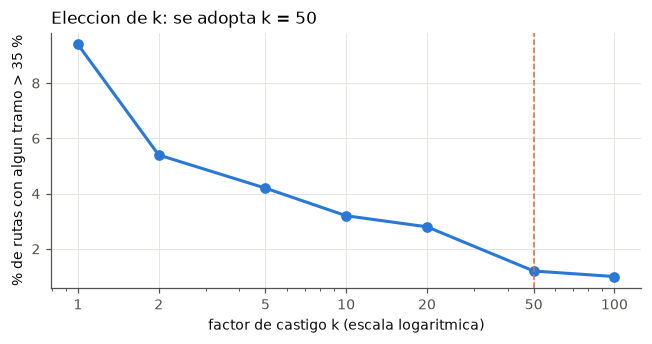

,k,pct_rutas_con_tramo_extremo,rutas_con_tramo_extremo,energia_real_media_kwh,pct_rutas_cambian_vs_k1,energia_real_extra_vs_k1_pct,distancia_extra_vs_k1_pct
0,1,9.4,47,1.89,0.0,0.00,0.00
1,2,5.4,27,1.89,4.8,0.04,0.06
2,5,4.2,21,1.89,5.6,0.20,0.18
3,10,3.2,16,1.90,6.4,0.42,0.34
4,20,2.8,14,1.90,7.0,0.44,0.36
5,50,1.2,6,1.90,8.6,0.79,0.60
6,100,1.0,5,1.90,8.8,0.87,0.66


rutas eficientes con extremo en 5.000 pares: 451 sin castigo y 1 con k = 50  (fuente: corridas del ruteo, .)
segmentos fuera de la componente fuertemente conexa: 10.867 (4,8 %)  (fuente: red propuesta del ruteo)
extremas fuera por localidad: San Cristobal 67, Ciudad Bolivar 36, Rafael Uribe Uribe 30, Usme 28  (fuente: red propuesta del ruteo)


In [91]:
if (RESPALDO / "D4_tabla_k.csv").exists():
    tk = pd.read_csv(RESPALDO / "D4_tabla_k.csv")
    meta = json.loads((RESPALDO / "D4_k_adoptado.json").read_text(encoding="utf-8"))
    pct = tk.set_index("k")["pct_rutas_con_tramo_extremo"]
    mostrar("% de rutas con tramo extremo sin castigo", meta["pct_rutas_con_extremo_sin_castigo"], 1)
    for k, v_ in zip([1, 2, 5, 10, 20, 50, 100], [9.4, 5.4, 4.2, 3.2, 2.8, 1.2, 1.0]):
        mostrar(f"% de rutas con tramo extremo, k = {k}", pct[k], 1)
    caidas = -pct.diff().shift(-1)
    k_regla = next(k for k in pct.index if (caidas.loc[k:].dropna() < 1).all())
    mostrar("k que resulta de la regla (recalculado)", k_regla)
    f50 = tk.set_index("k").loc[50]
    mostrar("rutas que siguen con un extremo, k = 50", f50["rutas_con_tramo_extremo"])
    mostrar("energia extra frente a k = 1 (%)", f50["energia_real_extra_vs_k1_pct"], 1)
    mostrar("distancia extra frente a k = 1 (%)", f50["distancia_extra_vs_k1_pct"], 1)
    bl = meta["bloquear_en_red_propuesta"]
    mostrar("bloquear: esquinas sin ruta", bl["esquinas_sin_ruta"])
    mostrar("bloquear: esquinas de la red", bl["esquinas_red_propuesta"])
    mostrar("bloquear: pares sin ruta", bl["pares_sin_ruta"])
    mostrar("filas extremas en la red de ruteo", meta["tramos_extremos"]["danna"])
    mostrar("filas extremas fuera de la componente conexa", len(ext) - meta["tramos_extremos"]["danna"])
    mostrar("extremas estimadas (68395_0, dos sentidos)", meta["tramos_extremos"]["estimados"])
    print("        pruebas del ruteo que pasan:", sum(p["pasa"] for p in meta["pruebas"]), "de", len(meta["pruebas"]))
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(pct.index, pct.values, "o-", color=AZUL, linewidth=2, markersize=6)
    ax.axvline(50, color=NARANJA, linewidth=1, linestyle="--")
    ax.set_xscale("log")
    ax.set_xticks(pct.index, [str(k) for k in pct.index])
    ax.set_xlabel("factor de castigo k (escala logaritmica)")
    ax.set_ylabel("% de rutas con algun tramo > 35 %")
    ax.set_title("Eleccion de k: se adopta k = 50", loc="left")
    plt.tight_layout()
    plt.show()
    display(tk.round(2))
else:
    print("Falta D4_tabla_k.csv en respaldo_eda.")
externa("rutas eficientes con extremo en 5.000 pares", "451 sin castigo y 1 con k = 50", "corridas del ruteo, .")
externa("segmentos fuera de la componente fuertemente conexa", "10.867 (4,8 %)", "red propuesta del ruteo")
externa("extremas fuera por localidad", "San Cristobal 67, Ciudad Bolivar 36, Rafael Uribe Uribe 30, Usme 28", "red propuesta del ruteo")

Los tramos de más de 35 % se mantienen en la red, pero se castigan al elegir la ruta multiplicando su peso por un factor k. Para elegir se rutean 500 viajes al azar con distintos valores, sin castigo, el 13,0 % de las rutas pasa por algún tramo extremo, con k = 1, el 9,4 %, y con k = 50, solo el 1,2 %. Se adoptó el menor k a partir del cual aumentarlo ya no reduce ese porcentaje en un punto o más, y la regla da k = 50. 
Evitar los tramos extremos cuesta poco, frente a k = 1, la energía de las rutas sube 0,8 % y la distancia 0,6 %. Bloquearlos, en cambio, dejar 594 esquinas sin ruta, se deja solo como sensibilidad. En la red de ruteo quedan 2.448 filas extremas castigadas.

### 9.2 Regla de puentes y túneles

Para usar el mismo criterio que en Medellín, los puentes y túneles solo se castigan cuando su neta supera 35 %. Resultado de *aux_regla_puentes_castigo.py*, las filas extremas sobre puente o túnel según OpenStreetMap y si siguen castigadas.

In [93]:
ruta_rp = AUX / "regla_puentes_castigo.csv"
if not ruta_rp.exists():
    ruta_rp = RESPALDO / "regla_puentes_castigo.csv"
if ruta_rp.exists():
    rp = leer(ruta_rp)
    rp["castigada_regla_medellin"] = verdadero(rp["castigada_regla_medellin"])
    salen = rp[~rp["castigada_regla_medellin"]]
    mostrar("filas extremas sobre puente o tunel", len(rp))
    mostrar("filas que dejan de castigarse", len(salen))
    mostrar("tramos fisicos que dejan de castigarse", salen["segmento_id"].str.rsplit("_", n=1).str[0].nunique())
    mostrar("neta del puente que sale (%)", salen["pendiente_neta_pct"].abs().max(), 1)
    mostrar("acumulada del puente que sale (%)", salen["pendiente_acumulada_pct"].max(), 1)
    mostrar("filas extremas castigadas con la regla", len(ext) - len(salen))
    display(rp)
else:
    print("Falta regla_puentes_castigo.csv.")
externa("aristas castigadas en la red de ruteo con la regla", "2.446 del archivo + 2 estimadas = 2.448 (antes 2.450)", "grafo")

filas extremas sobre puente o tunel: 6
filas que dejan de castigarse: 2
tramos fisicos que dejan de castigarse: 1
neta del puente que sale (%): 32.3
acumulada del puente que sale (%): 36.5
filas extremas castigadas con la regla: 2,639


,segmento_id,pendiente_neta_pct,pendiente_acumulada_pct,puente_osm,tunel_osm,castigada_regla_medellin
0,12427_0_FT,-32.286281,36.545073,True,False,False
1,12427_0_TF,32.286281,36.545073,True,False,False
2,144191_0_TF,-61.300646,61.300646,False,True,True
3,20423_0_TF,38.378417,38.378417,True,False,True
4,32110_0_FT,43.355179,43.355179,True,False,True
5,32110_0_TF,-43.355179,43.355179,True,False,True


aristas castigadas en la red de ruteo con la regla: 2.446 del archivo + 2 estimadas = 2.448 (antes 2.450)  (fuente: grafo)


### 9.3 Limitaciones

**Alturas estimadas en el borde** (D4_validacion_alturas_borde.csv). Se escondieron alturas conocidas cerca del borde de la cobertura y se estimaron con el método del grafo y con un promedio de las 8 esquinas más cercanas. Se reporta el error típico (mediana), el percentil 90 y el porcentaje de calles con error mayor de 5 puntos. Las demás limitaciones (σz por terreno, umbral de 2,64 m, ancho de 53,6 y 75,3 m) se calcularon en el capítulo 4.

In [94]:
if (RESPALDO / "D4_validacion_alturas_borde.csv").exists():
    vb = pd.read_csv(RESPALDO / "D4_validacion_alturas_borde.csv")
    g = vb[vb["metodo"] == "grafo"]
    mostrar("error tipico en el borde, minimo (pp)", g["pendiente_error_mediana_pp"].min(), 1)
    mostrar("error tipico en el borde, maximo (pp)", g["pendiente_error_mediana_pp"].max(), 1)
    mostrar("percentil 90, minimo (pp)", g["pendiente_error_p90_pp"].min(), 1)
    mostrar("percentil 90, maximo (pp)", g["pendiente_error_p90_pp"].max(), 1)
    mostrar("calles con error > 5 pp, minimo (%)", g["calles_error_mayor_5pp_pct"].min())
    mostrar("calles con error > 5 pp, maximo (%)", g["calles_error_mayor_5pp_pct"].max())
    f1 = vb[vb["franja_calles"] == 1].set_index("metodo")["pendiente_error_mediana_pp"]
    mostrar("franja 1, 8 esquinas mas cercanas (pp)", f1["knn_8"], 2)
    mostrar("franja 1, metodo del grafo (pp)", f1["grafo"], 2)
    display(vb)
mostrar("vertices en ladera", por_zona.loc["ladera (>8 %)", "size"])
mostrar("segmentos sin dato del MDT (%)", 100 * fuera.mean(), 1)
externa("esquinas estimadas entre el 1 % mas costoso para cargar", "26 %", "ruteo, zona rural de Usme")

error tipico en el borde, minimo (pp): 1.2
error tipico en el borde, maximo (pp): 1.7
percentil 90, minimo (pp): 11.7
percentil 90, maximo (pp): 13.4
calles con error > 5 pp, minimo (%): 27
calles con error > 5 pp, maximo (%): 33
franja 1, 8 esquinas mas cercanas (pp): 1.34
franja 1, metodo del grafo (pp): 1.69


,franja_calles,metodo,esquinas_escondidas,esquinas_no_estimables,calles_evaluadas,altura_error_mediana_m,altura_error_p90_m,pendiente_error_mediana_pp,pendiente_error_p90_pp,calles_error_mayor_5pp_pct
0,1,grafo,119,3,199,1.430,32.343,1.691,12.796,27.136
1,1,knn_8,119,3,199,1.446,31.039,1.341,14.021,31.658
2,2,grafo,258,8,418,1.605,32.234,1.248,11.720,28.230
3,2,knn_8,258,8,418,2.016,31.798,1.584,14.795,31.818
4,3,grafo,436,8,685,1.945,40.274,1.462,12.159,29.927
5,3,knn_8,436,8,685,1.892,41.238,1.537,13.404,32.701
6,5,grafo,874,8,1306,2.849,56.117,1.666,13.443,33.078
7,5,knn_8,874,8,1306,2.439,47.743,1.801,13.999,33.997


vertices en ladera: 81
segmentos sin dato del MDT (%): 0.6
esquinas estimadas entre el 1 % mas costoso para cargar: 26 %  (fuente: ruteo, zona rural de Usme)
